### Step 1 — Notebook configuration + ZIP validation

In [1]:
# ============================================================
# CELL 1 — IMPORTS
# ============================================================

from pathlib import Path
import os
import re
import zipfile
import random

import numpy as np
import pandas as pd

print("Environment initialized.")

Environment initialized.


In [2]:
# ============================================================
# CELL 2 — PROJECT CONFIGURATION
# ============================================================

# Change this ONE path if your project is somewhere else
PROJECT_ROOT = Path(r"C:\College\Projects\SN6_Multi-Sensor All-Weather Mapping")

# Data
RAW_DIR = PROJECT_ROOT / "data" / "raw"
METADATA_DIR = PROJECT_ROOT / "data" / "metadata"

# Outputs
OUTPUT_DIR = PROJECT_ROOT / "outputs"
FIGURES_DIR = OUTPUT_DIR / "figures"
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
METRICS_DIR = OUTPUT_DIR / "metrics"
PREDICTIONS_DIR = OUTPUT_DIR / "predictions"
LOGS_DIR = OUTPUT_DIR / "logs"

# Configuration
CONFIG_DIR = PROJECT_ROOT / "configs"

# ZIP files
SAR_ZIP = RAW_DIR / "SN6_25_SAR.zip"
OPTICAL_ZIP = RAW_DIR / "SN6_25_Optical.zip"
MASK_ZIP = RAW_DIR / "SN6_25_Masks.zip"

# Create required directories
for directory in [
    RAW_DIR,
    METADATA_DIR,
    FIGURES_DIR,
    CHECKPOINT_DIR,
    METRICS_DIR,
    PREDICTIONS_DIR,
    LOGS_DIR,
    CONFIG_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("SAR ZIP:", SAR_ZIP)
print("Optical ZIP:", OPTICAL_ZIP)
print("Mask ZIP:", MASK_ZIP)

Project root: C:\College\Projects\SN6_Multi-Sensor All-Weather Mapping
SAR ZIP: C:\College\Projects\SN6_Multi-Sensor All-Weather Mapping\data\raw\SN6_25_SAR.zip
Optical ZIP: C:\College\Projects\SN6_Multi-Sensor All-Weather Mapping\data\raw\SN6_25_Optical.zip
Mask ZIP: C:\College\Projects\SN6_Multi-Sensor All-Weather Mapping\data\raw\SN6_25_Masks.zip


In [3]:
# ============================================================
# CELL 3 — VERIFY INPUT ZIP FILES
# ============================================================

zip_files = {
    "SAR": SAR_ZIP,
    "Optical": OPTICAL_ZIP,
    "Mask": MASK_ZIP,
}

for name, path in zip_files.items():
    if not path.exists():
        raise FileNotFoundError(f"{name} ZIP not found: {path}")

    size_gb = path.stat().st_size / (1024 ** 3)

    print(f"{name:8s} | {size_gb:.2f} GB | {path.name}")

print("\nAll required ZIP files found.")

SAR      | 10.26 GB | SN6_25_SAR.zip
Optical  | 2.57 GB | SN6_25_Optical.zip
Mask     | 0.64 GB | SN6_25_Masks.zip

All required ZIP files found.


In [4]:
# ============================================================
# CELL 4 — INSPECT ZIP CONTENTS
# ============================================================

def inspect_zip(zip_path, label):
    with zipfile.ZipFile(zip_path, "r") as z:
        files = [
            name for name in z.namelist()
            if name.lower().endswith((".tif", ".tiff"))
        ]

    print(f"\n{label}")
    print("-" * 60)
    print("TIFF count:", len(files))

    print("\nFirst 3 files:")
    for f in files[:3]:
        print(" ", f)

    print("\nLast 3 files:")
    for f in files[-3:]:
        print(" ", f)

    return files


sar_files = inspect_zip(SAR_ZIP, "SAR")
optical_files = inspect_zip(OPTICAL_ZIP, "OPTICAL")
mask_files = inspect_zip(MASK_ZIP, "MASK")


SAR
------------------------------------------------------------
TIFF count: 850

First 3 files:
  SN6_Train_AOI_11_Rotterdam_SAR-Intensity_20190822162246_20190822162529_tile_7653.tif
  SN6_Train_AOI_11_Rotterdam_SAR-Intensity_20190804124148_20190804124417_tile_1326.tif
  SN6_Train_AOI_11_Rotterdam_SAR-Intensity_20190823150417_20190823150712_tile_10311.tif

Last 3 files:
  SN6_Train_AOI_11_Rotterdam_SAR-Intensity_20190823154802_20190823155103_tile_9756.tif
  SN6_Train_AOI_11_Rotterdam_SAR-Intensity_20190823152527_20190823152847_tile_5805.tif
  SN6_Train_AOI_11_Rotterdam_SAR-Intensity_20190822153558_20190822153835_tile_2542.tif

OPTICAL
------------------------------------------------------------
TIFF count: 850

First 3 files:
  SN6_Train_AOI_11_Rotterdam_PS-RGB_20190822162246_20190822162529_tile_7653.tif
  SN6_Train_AOI_11_Rotterdam_PS-RGB_20190804124148_20190804124417_tile_1326.tif
  SN6_Train_AOI_11_Rotterdam_PS-RGB_20190823150417_20190823150712_tile_10311.tif

Last 3 files:
  SN6_

In [5]:
# ============================================================
# CELL 5 — EXTRACT TILE IDS
# ============================================================

def extract_tile_id(filename):
    match = re.search(r"_tile_(\d+)\.tif{1,2}$", filename, re.IGNORECASE)

    if match is None:
        raise ValueError(f"Could not extract tile ID from: {filename}")

    return int(match.group(1))


def build_tile_map(files):
    tile_map = {}

    for filename in files:
        tile_id = extract_tile_id(filename)

        if tile_id in tile_map:
            raise ValueError(
                f"Duplicate tile ID {tile_id} found:\n"
                f"{tile_map[tile_id]}\n"
                f"{filename}"
            )

        tile_map[tile_id] = filename

    return tile_map


sar_map = build_tile_map(sar_files)
optical_map = build_tile_map(optical_files)
mask_map = build_tile_map(mask_files)

print("Unique SAR tile IDs:", len(sar_map))
print("Unique Optical tile IDs:", len(optical_map))
print("Unique Mask tile IDs:", len(mask_map))

Unique SAR tile IDs: 850
Unique Optical tile IDs: 850
Unique Mask tile IDs: 850


In [6]:
# ============================================================
# CELL 6 — VERIFY SAR / OPTICAL / MASK MATCHING
# ============================================================

sar_ids = set(sar_map)
optical_ids = set(optical_map)
mask_ids = set(mask_map)

common_ids = sar_ids & optical_ids & mask_ids

print("SAR IDs:", len(sar_ids))
print("Optical IDs:", len(optical_ids))
print("Mask IDs:", len(mask_ids))
print()
print("Common IDs:", len(common_ids))

missing_optical = sar_ids - optical_ids
missing_mask = sar_ids - mask_ids

print("SAR IDs missing Optical:", len(missing_optical))
print("SAR IDs missing Mask:", len(missing_mask))

# ------------------------------------------------------------
# Expected size of our WORKING 25% dataset
# ------------------------------------------------------------

EXPECTED_TILES = 850

if len(common_ids) != EXPECTED_TILES:
    raise RuntimeError(
        f"Expected {EXPECTED_TILES} fully matched tiles, "
        f"found {len(common_ids)}."
    )

if missing_optical:
    raise RuntimeError(
        f"{len(missing_optical)} SAR tiles are missing Optical."
    )

if missing_mask:
    raise RuntimeError(
        f"{len(missing_mask)} SAR tiles are missing Mask."
    )

print("\n✓ All 850 selected tiles have SAR + Optical + Mask.")
print("✓ Modality matching validated.")

SAR IDs: 850
Optical IDs: 850
Mask IDs: 850

Common IDs: 850
SAR IDs missing Optical: 0
SAR IDs missing Mask: 0

✓ All 850 selected tiles have SAR + Optical + Mask.
✓ Modality matching validated.


In [7]:
# ============================================================
# CELL 7 — CREATE MASTER TILE MANIFEST
# ============================================================

manifest = pd.DataFrame({
    "tile_id": sorted(common_ids)
})

manifest["sar_member"] = manifest["tile_id"].map(sar_map)
manifest["optical_member"] = manifest["tile_id"].map(optical_map)
manifest["mask_member"] = manifest["tile_id"].map(mask_map)

manifest_path = METADATA_DIR / "tile_manifest.csv"

manifest.to_csv(manifest_path, index=False)

print("Manifest saved to:")
print(manifest_path)

print("\nShape:", manifest.shape)

display(manifest.head())

Manifest saved to:
C:\College\Projects\SN6_Multi-Sensor All-Weather Mapping\data\metadata\tile_manifest.csv

Shape: (850, 4)


,tile_id,sar_member,optical_member,mask_member
0,3,SN6_Train_AOI_11_Rotterdam_SAR-Intensity_20190...,SN6_Train_AOI_11_Rotterdam_PS-RGB_201908221528...,SN6_Train_AOI_11_Rotterdam_SAR-Intensity_20190...
1,4,SN6_Train_AOI_11_Rotterdam_SAR-Intensity_20190...,SN6_Train_AOI_11_Rotterdam_PS-RGB_201908221528...,SN6_Train_AOI_11_Rotterdam_SAR-Intensity_20190...
2,9,SN6_Train_AOI_11_Rotterdam_SAR-Intensity_20190...,SN6_Train_AOI_11_Rotterdam_PS-RGB_201908221528...,SN6_Train_AOI_11_Rotterdam_SAR-Intensity_20190...
3,10,SN6_Train_AOI_11_Rotterdam_SAR-Intensity_20190...,SN6_Train_AOI_11_Rotterdam_PS-RGB_201908221528...,SN6_Train_AOI_11_Rotterdam_SAR-Intensity_20190...
4,12,SN6_Train_AOI_11_Rotterdam_SAR-Intensity_20190...,SN6_Train_AOI_11_Rotterdam_PS-RGB_201908221528...,SN6_Train_AOI_11_Rotterdam_SAR-Intensity_20190...


In [8]:
# ============================================================
# CELL 8 — MANIFEST VALIDATION
# ============================================================

assert len(manifest) == 850
assert manifest["tile_id"].is_unique
assert manifest["sar_member"].notna().all()
assert manifest["optical_member"].notna().all()
assert manifest["mask_member"].notna().all()

print("✓ Manifest row count: 850")
print("✓ Tile IDs are unique")
print("✓ Every tile has SAR")
print("✓ Every tile has Optical")
print("✓ Every tile has Mask")
print("\nMASTER MANIFEST VALIDATED.")

✓ Manifest row count: 850
✓ Tile IDs are unique
✓ Every tile has SAR
✓ Every tile has Optical
✓ Every tile has Mask

MASTER MANIFEST VALIDATED.


### Step 2 — Restore the Frozen Split

In [9]:
# ============================================================
# CELL 9 — LOAD FROZEN SPLIT CONFIGURATION
# ============================================================

import json

CONFIG_PATH = CONFIG_DIR / "preprocessing_config.json"

if not CONFIG_PATH.exists():
    raise FileNotFoundError(
        f"Frozen preprocessing config not found:\n{CONFIG_PATH}"
    )

with open(CONFIG_PATH, "r", encoding="utf-8") as f:
    preprocessing_config = json.load(f)

print("Frozen configuration loaded.")
print("Crop size:", preprocessing_config["crop_size"])

Frozen configuration loaded.
Crop size: [512, 512]


In [10]:
# ============================================================
# CELL 10 — EXTRACT FROZEN TRAIN / VAL / TEST IDS
# ============================================================

train_ids = set(preprocessing_config["splits"]["train_ids"])
val_ids   = set(preprocessing_config["splits"]["val_ids"])
test_ids  = set(preprocessing_config["splits"]["test_ids"])

print("Frozen split sizes:")
print("Train:", len(train_ids))
print("Validation:", len(val_ids))
print("Test:", len(test_ids))

Frozen split sizes:
Train: 595
Validation: 127
Test: 128


In [11]:
# ============================================================
# CELL 10 — EXTRACT FROZEN TRAIN / VAL / TEST IDS
# ============================================================

train_ids = {int(x) for x in preprocessing_config["splits"]["train_ids"]}
val_ids   = {int(x) for x in preprocessing_config["splits"]["val_ids"]}
test_ids  = {int(x) for x in preprocessing_config["splits"]["test_ids"]}

print("Frozen split sizes:")
print("Train:", len(train_ids))
print("Validation:", len(val_ids))
print("Test:", len(test_ids))

Frozen split sizes:
Train: 595
Validation: 127
Test: 128


In [12]:
# ============================================================
# CELL 11 — VALIDATE FROZEN SPLIT
# ============================================================

manifest_ids = set(manifest["tile_id"].astype(int))

# Check that every split ID exists in our 850-tile manifest
missing_train = train_ids - manifest_ids
missing_val   = val_ids - manifest_ids
missing_test  = test_ids - manifest_ids

print("Missing train IDs:", len(missing_train))
print("Missing val IDs:", len(missing_val))
print("Missing test IDs:", len(missing_test))

if missing_train:
    print("Example missing train IDs:", sorted(missing_train)[:10])

if missing_val:
    print("Example missing validation IDs:", sorted(missing_val)[:10])

if missing_test:
    print("Example missing test IDs:", sorted(missing_test)[:10])

# No split overlap
assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

# Check membership
if missing_train or missing_val or missing_test:
    raise RuntimeError(
        "The frozen split contains tile IDs that are not present "
        "in the 850-tile working subset."
    )

assert len(train_ids | val_ids | test_ids) == 850

print("\n✓ All frozen IDs exist in the 850-tile manifest")
print("✓ Train / validation / test have no overlap")
print("✓ All 850 tiles are covered")

Missing train IDs: 0
Missing val IDs: 0
Missing test IDs: 0

✓ All frozen IDs exist in the 850-tile manifest
✓ Train / validation / test have no overlap
✓ All 850 tiles are covered


In [13]:
# ============================================================
# CELL 12 — CREATE FROZEN SPLIT CSV FILES
# ============================================================

def create_split_csv(manifest_df, tile_ids, split_name):
    split_df = manifest_df[
        manifest_df["tile_id"].isin(tile_ids)
    ].copy()

    split_df["split"] = split_name
    split_df = split_df.sort_values("tile_id").reset_index(drop=True)

    output_path = METADATA_DIR / f"{split_name}.csv"
    split_df.to_csv(output_path, index=False)

    print(
        f"{split_name:10s}: "
        f"{len(split_df):3d} tiles → {output_path.name}"
    )

    return split_df


train_df = create_split_csv(
    manifest,
    train_ids,
    "train"
)

val_df = create_split_csv(
    manifest,
    val_ids,
    "val"
)

test_df = create_split_csv(
    manifest,
    test_ids,
    "test"
)

train     : 595 tiles → train.csv
val       : 127 tiles → val.csv
test      : 128 tiles → test.csv


In [14]:
# ============================================================
# CELL 13 — FINAL SPLIT VERIFICATION
# ============================================================

assert len(train_df) == 595
assert len(val_df) == 127
assert len(test_df) == 128

assert len(train_df) + len(val_df) + len(test_df) == 850

assert set(train_df["tile_id"]).isdisjoint(set(val_df["tile_id"]))
assert set(train_df["tile_id"]).isdisjoint(set(test_df["tile_id"]))
assert set(val_df["tile_id"]).isdisjoint(set(test_df["tile_id"]))

print("=" * 60)
print("FROZEN DATASET SPLIT VALIDATED")
print("=" * 60)
print(f"Train:      {len(train_df)}")
print(f"Validation: {len(val_df)}")
print(f"Test:       {len(test_df)}")
print(f"Total:      {len(train_df) + len(val_df) + len(test_df)}")
print("=" * 60)

FROZEN DATASET SPLIT VALIDATED
Train:      595
Validation: 127
Test:       128
Total:      850


### Step 3 — ZIP-direct TIFF reader

In [15]:
# ============================================================
# CELL 14 — ZIP-DIRECT TIFF READER
# ============================================================

import zipfile
import rasterio
from rasterio.io import MemoryFile
import numpy as np


def read_tiff_from_zip(zip_path, member_name):
    """
    Read a TIFF directly from a ZIP archive into memory.
    No extraction to disk.
    """
    with zipfile.ZipFile(zip_path, "r") as z:
        data = z.read(member_name)

    with MemoryFile(data) as memfile:
        with memfile.open() as src:
            array = src.read()

            metadata = {
                "shape": array.shape,
                "dtype": str(array.dtype),
                "crs": str(src.crs),
                "transform": src.transform,
                "nodata": src.nodata,
                "count": src.count,
                "width": src.width,
                "height": src.height,
            }

    return array, metadata


print("✓ ZIP-direct TIFF reader ready")

✓ ZIP-direct TIFF reader ready


In [16]:
# ============================================================
# CELL 15 — READ SAMPLE TILE
# ============================================================

sample_row = train_df.iloc[0]

sar, sar_meta = read_tiff_from_zip(
    SAR_ZIP,
    sample_row["sar_member"]
)

optical, optical_meta = read_tiff_from_zip(
    OPTICAL_ZIP,
    sample_row["optical_member"]
)

mask, mask_meta = read_tiff_from_zip(
    MASK_ZIP,
    sample_row["mask_member"]
)

print("Tile ID:", sample_row["tile_id"])

print("\nSAR")
print("Shape:", sar.shape)
print("Dtype:", sar.dtype)
print("Min:", np.nanmin(sar))
print("Max:", np.nanmax(sar))

print("\nOptical")
print("Shape:", optical.shape)
print("Dtype:", optical.dtype)
print("Min:", np.nanmin(optical))
print("Max:", np.nanmax(optical))

print("\nMask")
print("Shape:", mask.shape)
print("Dtype:", mask.dtype)
print("Unique values:", np.unique(mask)[:20])

Tile ID: 3

SAR
Shape: (4, 900, 900)
Dtype: float32
Min: 0.0
Max: 77.52799

Optical
Shape: (4, 900, 900)
Dtype: uint8
Min: 0
Max: 255

Mask
Shape: (1, 900, 900)
Dtype: uint8
Unique values: [  0 255]


In [17]:
# ============================================================
# CELL 16 — TIFF METADATA
# ============================================================

print("=" * 60)
print("SAR METADATA")
print("=" * 60)

for key, value in sar_meta.items():
    print(f"{key}: {value}")

print("\n" + "=" * 60)
print("OPTICAL METADATA")
print("=" * 60)

for key, value in optical_meta.items():
    print(f"{key}: {value}")

print("\n" + "=" * 60)
print("MASK METADATA")
print("=" * 60)

for key, value in mask_meta.items():
    print(f"{key}: {value}")

SAR METADATA
shape: (4, 900, 900)
dtype: float32
crs: EPSG:32631
transform: | 0.50, 0.00, 593017.44|
| 0.00,-0.50, 5748635.17|
| 0.00, 0.00, 1.00|
nodata: 0.0
count: 4
width: 900
height: 900

OPTICAL METADATA
shape: (4, 900, 900)
dtype: uint8
crs: EPSG:32631
transform: | 0.50, 0.00, 593017.44|
| 0.00,-0.50, 5748635.17|
| 0.00, 0.00, 1.00|
nodata: None
count: 4
width: 900
height: 900

MASK METADATA
shape: (1, 900, 900)
dtype: uint8
crs: EPSG:32631
transform: | 0.50, 0.00, 593017.44|
| 0.00,-0.50, 5748635.17|
| 0.00, 0.00, 1.00|
nodata: 0.0
count: 1
width: 900
height: 900


In [18]:
# ============================================================
# CELL 17 — RAW VALUE DISTRIBUTION
# ============================================================

def print_value_stats(name, array):
    x = array.astype(np.float32)

    finite = x[np.isfinite(x)]

    print(f"\n{name}")
    print("-" * 50)
    print("Shape:", array.shape)
    print("Dtype:", array.dtype)
    print("Min:", finite.min())
    print("Max:", finite.max())

    print("Percentiles:")
    for p in [0, 1, 2, 5, 25, 50, 75, 95, 98, 99, 100]:
        print(f"  P{p:>3}: {np.percentile(finite, p):.4f}")


print_value_stats("SAR", sar)
print_value_stats("OPTICAL", optical)
print_value_stats("MASK", mask)


SAR
--------------------------------------------------
Shape: (4, 900, 900)
Dtype: float32
Min: 0.0
Max: 77.52799
Percentiles:
  P  0: 0.0000
  P  1: 0.0000
  P  2: 0.0000
  P  5: 0.0000
  P 25: 0.0000
  P 50: 23.6220
  P 75: 38.5860
  P 95: 44.1920
  P 98: 46.2148
  P 99: 47.8038
  P100: 77.5280

OPTICAL
--------------------------------------------------
Shape: (4, 900, 900)
Dtype: uint8
Min: 0.0
Max: 255.0
Percentiles:
  P  0: 0.0000
  P  1: 0.0000
  P  2: 0.0000
  P  5: 0.0000
  P 25: 0.0000
  P 50: 85.0000
  P 75: 131.0000
  P 95: 172.0000
  P 98: 192.0000
  P 99: 211.0000
  P100: 255.0000

MASK
--------------------------------------------------
Shape: (1, 900, 900)
Dtype: uint8
Min: 0.0
Max: 255.0
Percentiles:
  P  0: 0.0000
  P  1: 0.0000
  P  2: 0.0000
  P  5: 0.0000
  P 25: 0.0000
  P 50: 0.0000
  P 75: 0.0000
  P 95: 255.0000
  P 98: 255.0000
  P 99: 255.0000
  P100: 255.0000


In [19]:
# ============================================================
# CELL 18 — TRAINING SET RAW DATA VALIDATION
# ============================================================

def get_valid_sar_values(array):
    """
    SAR nodata = 0.
    Return only finite, non-nodata values.
    """
    x = array.astype(np.float32)

    valid = np.isfinite(x) & (x != 0)

    return x[valid]


sample_ids = train_df["tile_id"].tolist()

sar_min = np.inf
sar_max = -np.inf

opt_min = np.inf
opt_max = -np.inf

mask_values = set()

sar_nodata_pixels = 0
sar_total_pixels = 0

building_pixels = 0
mask_total_pixels = 0

print(f"Validating {len(sample_ids)} training tiles...\n")

for idx, row in train_df.iterrows():

    # ---------- SAR ----------
    sar, _ = read_tiff_from_zip(
        SAR_ZIP,
        row["sar_member"]
    )

    valid_sar = get_valid_sar_values(sar)

    if len(valid_sar) > 0:
        sar_min = min(sar_min, valid_sar.min())
        sar_max = max(sar_max, valid_sar.max())

    sar_nodata_pixels += np.sum(sar == 0)
    sar_total_pixels += sar.size

    # ---------- Optical ----------
    optical, _ = read_tiff_from_zip(
        OPTICAL_ZIP,
        row["optical_member"]
    )

    opt_min = min(opt_min, optical.min())
    opt_max = max(opt_max, optical.max())

    # ---------- Mask ----------
    mask, _ = read_tiff_from_zip(
        MASK_ZIP,
        row["mask_member"]
    )

    mask_values.update(np.unique(mask).tolist())

    building_pixels += np.sum(mask > 0)
    mask_total_pixels += mask.size

    if (idx + 1) % 50 == 0:
        print(f"Processed {idx + 1}/{len(train_df)}")


sar_nodata_pct = 100 * sar_nodata_pixels / sar_total_pixels
building_pct = 100 * building_pixels / mask_total_pixels

print("\n" + "=" * 60)
print("TRAINING DATA VALIDATION")
print("=" * 60)

print(f"SAR valid min:       {sar_min:.4f}")
print(f"SAR valid max:       {sar_max:.4f}")
print(f"SAR nodata:          {sar_nodata_pct:.4f}%")

print(f"\nOptical min:         {opt_min}")
print(f"Optical max:         {opt_max}")

print(f"\nMask unique values:  {sorted(mask_values)}")
print(f"Building pixels:    {building_pct:.4f}%")

print("=" * 60)

Validating 595 training tiles...

Processed 50/595
Processed 100/595
Processed 150/595
Processed 200/595
Processed 250/595
Processed 300/595
Processed 350/595
Processed 400/595
Processed 450/595
Processed 500/595
Processed 550/595

TRAINING DATA VALIDATION
SAR valid min:       0.0000
SAR valid max:       90.5630
SAR nodata:          33.8749%

Optical min:         0
Optical max:         255

Mask unique values:  [0, 255]
Building pixels:    6.4261%


In [20]:
# ============================================================
# CELL 19 — SAR dB TRANSFORMATION VALIDATION
# ============================================================

EPS = 1e-6

sar_db_min = np.inf
sar_db_max = -np.inf

sar_db_samples = []

print(f"Processing {len(train_df)} training tiles...")

for idx, row in train_df.iterrows():

    sar, _ = read_tiff_from_zip(
        SAR_ZIP,
        row["sar_member"]
    )

    sar = sar.astype(np.float32)

    # Valid SAR pixels
    valid = np.isfinite(sar) & (sar != 0)

    # Convert only valid pixels to dB
    sar_db = np.zeros_like(sar, dtype=np.float32)

    sar_db[valid] = 10.0 * np.log10(
        sar[valid] + EPS
    )

    valid_db = sar_db[valid]

    sar_db_min = min(sar_db_min, valid_db.min())
    sar_db_max = max(sar_db_max, valid_db.max())

    # Keep a small sample for distribution inspection
    if idx < 20:
        sample = valid_db.flatten()

        if len(sample) > 50000:
            sample = np.random.default_rng(42).choice(
                sample,
                size=50000,
                replace=False
            )

        sar_db_samples.append(sample)

    if (idx + 1) % 100 == 0:
        print(f"Processed {idx + 1}/{len(train_df)}")


sar_db_samples = np.concatenate(sar_db_samples)

print("\n" + "=" * 60)
print("SAR dB TRANSFORMATION")
print("=" * 60)

print(f"Minimum dB: {sar_db_min:.4f}")
print(f"Maximum dB: {sar_db_max:.4f}")

print("\nSample distribution:")

for p in [1, 2, 5, 25, 50, 75, 95, 98, 99, 100]:
    print(
        f"P{p:>3}: "
        f"{np.percentile(sar_db_samples, p):.4f}"
    )

print("=" * 60)

Processing 595 training tiles...
Processed 100/595
Processed 200/595
Processed 300/595
Processed 400/595
Processed 500/595

SAR dB TRANSFORMATION
Minimum dB: -49.5861
Maximum dB: 19.5695

Sample distribution:
P  1: 11.5499
P  2: 11.9660
P  5: 12.5430
P 25: 13.8664
P 50: 14.9568
P 75: 15.9173
P 95: 16.5879
P 98: 16.8960
P 99: 17.0818
P100: 18.8901


In [21]:
# ============================================================
# CELL 20 — FINAL SAR TRAINING STATISTICS
# ============================================================

EPS = 1e-6

sar_values = [[] for _ in range(4)]

print(f"Calculating statistics from {len(train_df)} training tiles...")

for idx, row in train_df.iterrows():

    sar, _ = read_tiff_from_zip(
        SAR_ZIP,
        row["sar_member"]
    )

    sar = sar.astype(np.float32)

    for c in range(4):

        channel = sar[c]

        valid = np.isfinite(channel) & (channel != 0)

        valid_values = channel[valid]

        # Convert valid pixels to dB
        db_values = 10.0 * np.log10(
            valid_values + EPS
        )

        sar_values[c].append(db_values)

    if (idx + 1) % 100 == 0:
        print(f"Processed {idx + 1}/{len(train_df)}")


sar_stats = {}

for c in range(4):

    values = np.concatenate(sar_values[c])

    mean = float(np.mean(values))
    std = float(np.std(values))

    p2 = float(np.percentile(values, 2))
    p98 = float(np.percentile(values, 98))

    sar_stats[f"band_{c+1}"] = {
        "mean": mean,
        "std": std,
        "p2": p2,
        "p98": p98
    }

    print(f"\nSAR Band {c+1}")
    print(f"Mean: {mean:.6f}")
    print(f"Std:  {std:.6f}")
    print(f"P2:   {p2:.6f}")
    print(f"P98:  {p98:.6f}")

print("\n✓ Final SAR training statistics calculated")

Calculating statistics from 595 training tiles...
Processed 100/595
Processed 200/595
Processed 300/595
Processed 400/595
Processed 500/595

SAR Band 1
Mean: 14.416707
Std:  1.246230
P2:   11.355271
P98:  16.480953

SAR Band 2
Mean: 15.577549
Std:  0.808152
P2:   13.613934
P98:  16.976120

SAR Band 3
Mean: 15.272163
Std:  0.909840
P2:   13.017539
P98:  16.809351

SAR Band 4
Mean: 14.009843
Std:  1.489323
P2:   10.395216
P98:  16.330704

✓ Final SAR training statistics calculated


In [22]:
# ============================================================
# CELL 21 — SAVE VERIFIED SAR STATISTICS
# ============================================================

preprocessing_stats = {
    "sar": {
        "bands": 4,
        "transform": "10log10",
        "nodata": 0.0,
        "epsilon": EPS,
        "clip_p2": [
            sar_stats["band_1"]["p2"],
            sar_stats["band_2"]["p2"],
            sar_stats["band_3"]["p2"],
            sar_stats["band_4"]["p2"],
        ],
        "clip_p98": [
            sar_stats["band_1"]["p98"],
            sar_stats["band_2"]["p98"],
            sar_stats["band_3"]["p98"],
            sar_stats["band_4"]["p98"],
        ],
        "mean": [
            sar_stats["band_1"]["mean"],
            sar_stats["band_2"]["mean"],
            sar_stats["band_3"]["mean"],
            sar_stats["band_4"]["mean"],
        ],
        "std": [
            sar_stats["band_1"]["std"],
            sar_stats["band_2"]["std"],
            sar_stats["band_3"]["std"],
            sar_stats["band_4"]["std"],
        ],
    }
}

stats_path = METADATA_DIR / "verified_preprocessing_stats.json"

import json

with open(stats_path, "w") as f:
    json.dump(preprocessing_stats, f, indent=2)

print(f"✓ Saved verified statistics to:")
print(stats_path)

✓ Saved verified statistics to:
C:\College\Projects\SN6_Multi-Sensor All-Weather Mapping\data\metadata\verified_preprocessing_stats.json


In [23]:
# ============================================================
# CELL 22 — OPTICAL TRAINING STATISTICS
# ============================================================

optical_values = [[] for _ in range(4)]

print(f"Calculating optical statistics from {len(train_df)} training tiles...")

for idx, row in train_df.iterrows():

    optical, _ = read_tiff_from_zip(
        OPTICAL_ZIP,
        row["optical_member"]
    )

    optical = optical.astype(np.float32)

    # Convert uint8 [0,255] → [0,1]
    optical = optical / 255.0

    for c in range(4):
        optical_values[c].append(
            optical[c].reshape(-1)
        )

    if (idx + 1) % 100 == 0:
        print(f"Processed {idx + 1}/{len(train_df)}")


optical_stats = {}

for c in range(4):

    values = np.concatenate(optical_values[c])

    mean = float(np.mean(values))
    std = float(np.std(values))

    p2 = float(np.percentile(values, 2))
    p98 = float(np.percentile(values, 98))

    optical_stats[f"band_{c+1}"] = {
        "mean": mean,
        "std": std,
        "p2": p2,
        "p98": p98
    }

    print(f"\nOptical Band {c+1}")
    print(f"Mean: {mean:.6f}")
    print(f"Std:  {std:.6f}")
    print(f"P2:   {p2:.6f}")
    print(f"P98:  {p98:.6f}")

print("\n✓ Final optical training statistics calculated")

Calculating optical statistics from 595 training tiles...
Processed 100/595
Processed 200/595
Processed 300/595
Processed 400/595
Processed 500/595

Optical Band 1
Mean: 0.240672
Std:  0.222002
P2:   0.000000
P98:  0.768627

Optical Band 2
Mean: 0.249975
Std:  0.235076
P2:   0.000000
P98:  0.796078

Optical Band 3
Mean: 0.249975
Std:  0.235076
P2:   0.000000
P98:  0.796078

Optical Band 4
Mean: 0.264730
Std:  0.230385
P2:   0.000000
P98:  0.768627

✓ Final optical training statistics calculated


In [24]:
# ============================================================
# CELL 23 — SAVE FINAL VERIFIED PREPROCESSING STATISTICS
# ============================================================

preprocessing_stats["optical"] = {
    "bands": 4,
    "scale": 255.0,
    "clip_p2": [
        optical_stats["band_1"]["p2"],
        optical_stats["band_2"]["p2"],
        optical_stats["band_3"]["p2"],
        optical_stats["band_4"]["p2"],
    ],
    "clip_p98": [
        optical_stats["band_1"]["p98"],
        optical_stats["band_2"]["p98"],
        optical_stats["band_3"]["p98"],
        optical_stats["band_4"]["p98"],
    ],
    "mean": [
        optical_stats["band_1"]["mean"],
        optical_stats["band_2"]["mean"],
        optical_stats["band_3"]["mean"],
        optical_stats["band_4"]["mean"],
    ],
    "std": [
        optical_stats["band_1"]["std"],
        optical_stats["band_2"]["std"],
        optical_stats["band_3"]["std"],
        optical_stats["band_4"]["std"],
    ],
}

with open(stats_path, "w") as f:
    json.dump(preprocessing_stats, f, indent=2)

print("=" * 60)
print("FINAL PREPROCESSING STATISTICS SAVED")
print("=" * 60)
print(stats_path)
print("\n✓ SAR statistics saved")
print("✓ Optical statistics saved")
print("✓ Training-only statistics")
print("✓ No validation/test data used")

FINAL PREPROCESSING STATISTICS SAVED
C:\College\Projects\SN6_Multi-Sensor All-Weather Mapping\data\metadata\verified_preprocessing_stats.json

✓ SAR statistics saved
✓ Optical statistics saved
✓ Training-only statistics
✓ No validation/test data used


In [25]:
# ============================================================
# CELL 24 — FINAL PREPROCESSING FUNCTIONS
# ============================================================

SAR_MEAN = np.array(preprocessing_stats["sar"]["mean"], dtype=np.float32)
SAR_STD  = np.array(preprocessing_stats["sar"]["std"], dtype=np.float32)
SAR_P2   = np.array(preprocessing_stats["sar"]["clip_p2"], dtype=np.float32)
SAR_P98  = np.array(preprocessing_stats["sar"]["clip_p98"], dtype=np.float32)

OPT_MEAN = np.array(preprocessing_stats["optical"]["mean"], dtype=np.float32)
OPT_STD  = np.array(preprocessing_stats["optical"]["std"], dtype=np.float32)
OPT_P2   = np.array(preprocessing_stats["optical"]["clip_p2"], dtype=np.float32)
OPT_P98  = np.array(preprocessing_stats["optical"]["clip_p98"], dtype=np.float32)

EPS = preprocessing_stats["sar"]["epsilon"]


def preprocess_sar(sar):
    """
    SAR preprocessing:
    raw intensity → dB → percentile clipping → z-score

    Input:
        (4, H, W) float32

    Output:
        (4, H, W) float32
    """

    sar = sar.astype(np.float32)

    output = np.zeros_like(sar, dtype=np.float32)

    for c in range(4):

        channel = sar[c]

        valid = np.isfinite(channel) & (channel != 0)

        if np.any(valid):

            # Raw intensity → dB
            db = np.zeros_like(channel, dtype=np.float32)

            db[valid] = 10.0 * np.log10(
                channel[valid] + EPS
            )

            # Clip only valid pixels
            db[valid] = np.clip(
                db[valid],
                SAR_P2[c],
                SAR_P98[c]
            )

            # Normalize only valid pixels
            db[valid] = (
                db[valid] - SAR_MEAN[c]
            ) / SAR_STD[c]

            output[c] = db

            # Keep nodata pixels at zero
            output[c][~valid] = 0.0

    return output


def preprocess_optical(optical):
    """
    Optical preprocessing:
    uint8 → [0,1] → percentile clipping → z-score

    Input:
        (4, H, W) uint8

    Output:
        (4, H, W) float32
    """

    optical = optical.astype(np.float32) / 255.0

    for c in range(4):

        optical[c] = np.clip(
            optical[c],
            OPT_P2[c],
            OPT_P98[c]
        )

        optical[c] = (
            optical[c] - OPT_MEAN[c]
        ) / OPT_STD[c]

    return optical.astype(np.float32)


def preprocess_mask(mask):
    """
    Convert binary {0,255} mask → {0,1} float32.

    Input:
        (1, H, W)

    Output:
        (H, W) float32
    """

    mask = (mask[0] > 0).astype(np.float32)

    return mask


print("✓ SAR preprocessing function ready")
print("✓ Optical preprocessing function ready")
print("✓ Mask preprocessing function ready")

✓ SAR preprocessing function ready
✓ Optical preprocessing function ready
✓ Mask preprocessing function ready


In [26]:
# ============================================================
# CELL 25 — TEST PREPROCESSING
# ============================================================

sar_processed = preprocess_sar(sar)
optical_processed = preprocess_optical(optical)
mask_processed = preprocess_mask(mask)

print("=" * 60)
print("PREPROCESSING TEST")
print("=" * 60)

print("\nSAR")
print("Shape:", sar_processed.shape)
print("Dtype:", sar_processed.dtype)
print("Min:", np.min(sar_processed))
print("Max:", np.max(sar_processed))

print("\nOptical")
print("Shape:", optical_processed.shape)
print("Dtype:", optical_processed.dtype)
print("Min:", np.min(optical_processed))
print("Max:", np.max(optical_processed))

print("\nMask")
print("Shape:", mask_processed.shape)
print("Dtype:", mask_processed.dtype)
print("Unique:", np.unique(mask_processed))

print("=" * 60)

PREPROCESSING TEST

SAR
Shape: (4, 900, 900)
Dtype: float32
Min: -2.4565575
Max: 1.73058

Optical
Shape: (4, 900, 900)
Dtype: float32
Min: -1.1490744
Max: -1.0466998

Mask
Shape: (900, 900)
Dtype: float32
Unique: [0. 1.]


In [27]:
# ============================================================
# CELL 26 — SYNCHRONIZED 512×512 CROP
# ============================================================

CROP_SIZE = 512


def random_crop_triplet(sar, optical, mask, crop_size=512):
    """
    Apply the exact same random crop to SAR, optical, and mask.

    SAR:
        (4, H, W)

    Optical:
        (4, H, W)

    Mask:
        (H, W)
    """

    _, h, w = sar.shape

    if h < crop_size or w < crop_size:
        raise ValueError(
            f"Image size {(h, w)} is smaller than crop size {crop_size}"
        )

    top = np.random.randint(
        0,
        h - crop_size + 1
    )

    left = np.random.randint(
        0,
        w - crop_size + 1
    )

    sar_crop = sar[
        :,
        top:top + crop_size,
        left:left + crop_size
    ]

    optical_crop = optical[
        :,
        top:top + crop_size,
        left:left + crop_size
    ]

    mask_crop = mask[
        top:top + crop_size,
        left:left + crop_size
    ]

    return sar_crop, optical_crop, mask_crop


print("✓ Synchronized 512×512 crop function ready")

✓ Synchronized 512×512 crop function ready


In [28]:
# ============================================================
# CELL 27 — TEST SYNCHRONIZED CROP
# ============================================================

np.random.seed(42)

sar_crop, optical_crop, mask_crop = random_crop_triplet(
    sar_processed,
    optical_processed,
    mask_processed,
    CROP_SIZE
)

print("=" * 60)
print("CROP TEST")
print("=" * 60)

print("SAR:", sar_crop.shape)
print("Optical:", optical_crop.shape)
print("Mask:", mask_crop.shape)

print("\nSAR dtype:", sar_crop.dtype)
print("Optical dtype:", optical_crop.dtype)
print("Mask dtype:", mask_crop.dtype)

print("\nMask unique values:", np.unique(mask_crop))

assert sar_crop.shape == (4, 512, 512)
assert optical_crop.shape == (4, 512, 512)
assert mask_crop.shape == (512, 512)

print("\n✓ All modalities are spatially synchronized")
print("✓ Crop size = 512×512")

CROP TEST
SAR: (4, 512, 512)
Optical: (4, 512, 512)
Mask: (512, 512)

SAR dtype: float32
Optical dtype: float32
Mask dtype: float32

Mask unique values: [0. 1.]

✓ All modalities are spatially synchronized
✓ Crop size = 512×512


In [29]:
# ============================================================
# CELL 28 — MINIMAL PAIRED AUGMENTATION
# ============================================================

def augment_triplet(sar, optical, mask):
    """
    Apply identical geometric augmentation to all modalities.
    """

    # Horizontal flip
    if np.random.rand() < 0.5:
        sar = np.flip(sar, axis=2).copy()
        optical = np.flip(optical, axis=2).copy()
        mask = np.flip(mask, axis=1).copy()

    # Vertical flip
    if np.random.rand() < 0.5:
        sar = np.flip(sar, axis=1).copy()
        optical = np.flip(optical, axis=1).copy()
        mask = np.flip(mask, axis=0).copy()

    # Random 90-degree rotation
    k = np.random.randint(0, 4)

    if k > 0:
        sar = np.rot90(sar, k=k, axes=(1, 2)).copy()
        optical = np.rot90(optical, k=k, axes=(1, 2)).copy()
        mask = np.rot90(mask, k=k, axes=(0, 1)).copy()

    return sar, optical, mask


print("✓ Minimal paired augmentation ready")

✓ Minimal paired augmentation ready


In [30]:
# ============================================================
# CELL 29 — PYTORCH DATASET
# ============================================================

import torch
from torch.utils.data import Dataset, DataLoader


class SN6Dataset(Dataset):

    def __init__(
        self,
        dataframe,
        training=False,
        crop_size=512
    ):
        self.df = dataframe.reset_index(drop=True)
        self.training = training
        self.crop_size = crop_size

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        # -----------------------------
        # Read directly from ZIP
        # -----------------------------

        sar, _ = read_tiff_from_zip(
            SAR_ZIP,
            row["sar_member"]
        )

        optical, _ = read_tiff_from_zip(
            OPTICAL_ZIP,
            row["optical_member"]
        )

        mask, _ = read_tiff_from_zip(
            MASK_ZIP,
            row["mask_member"]
        )

        # -----------------------------
        # Preprocessing
        # -----------------------------

        sar = preprocess_sar(sar)
        optical = preprocess_optical(optical)
        mask = preprocess_mask(mask)

        # -----------------------------
        # Crop
        # -----------------------------

        if self.training:

            sar, optical, mask = random_crop_triplet(
                sar,
                optical,
                mask,
                self.crop_size
            )

            sar, optical, mask = augment_triplet(
                sar,
                optical,
                mask
            )

        else:

            # Deterministic center crop
            h, w = mask.shape

            top = (h - self.crop_size) // 2
            left = (w - self.crop_size) // 2

            sar = sar[
                :,
                top:top+self.crop_size,
                left:left+self.crop_size
            ]

            optical = optical[
                :,
                top:top+self.crop_size,
                left:left+self.crop_size
            ]

            mask = mask[
                top:top+self.crop_size,
                left:left+self.crop_size
            ]

        # -----------------------------
        # NumPy → PyTorch
        # -----------------------------

        sar = torch.from_numpy(
            sar.copy()
        ).float()

        optical = torch.from_numpy(
            optical.copy()
        ).float()

        mask = torch.from_numpy(
            mask.copy()
        ).float()

        return {
            "sar": sar,
            "optical": optical,
            "mask": mask,
            "tile_id": int(row["tile_id"])
        }


print("✓ SN6Dataset ready")

✓ SN6Dataset ready


In [31]:
# ============================================================
# CELL 30 — DATALOADERS
# ============================================================

BATCH_SIZE = 4

train_dataset = SN6Dataset(
    train_df,
    training=True
)

val_dataset = SN6Dataset(
    val_df,
    training=False
)

test_dataset = SN6Dataset(
    test_df,
    training=False
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print("✓ DataLoaders created")

print("\nDataset sizes:")
print("Train:", len(train_dataset))
print("Val:  ", len(val_dataset))
print("Test: ", len(test_dataset))

✓ DataLoaders created

Dataset sizes:
Train: 595
Val:   127
Test:  128


In [32]:
# ============================================================
# CELL 31 — DATALOADER SANITY CHECK
# ============================================================

batch = next(iter(train_loader))

print("=" * 60)
print("BATCH SANITY CHECK")
print("=" * 60)

print("SAR:     ", batch["sar"].shape)
print("Optical: ", batch["optical"].shape)
print("Mask:    ", batch["mask"].shape)
print("Tile IDs:", batch["tile_id"])

print("\nSAR dtype:", batch["sar"].dtype)
print("Optical dtype:", batch["optical"].dtype)
print("Mask dtype:", batch["mask"].dtype)

print("\nMask unique values:",
      torch.unique(batch["mask"]))

assert batch["sar"].shape == (BATCH_SIZE, 4, 512, 512)
assert batch["optical"].shape == (BATCH_SIZE, 4, 512, 512)
assert batch["mask"].shape == (BATCH_SIZE, 512, 512)

print("\n✓ Dataset pipeline working")
print("✓ SAR = 4 channels")
print("✓ Optical = 4 channels")
print("✓ Mask = binary")
print("✓ 512×512")

BATCH SANITY CHECK
SAR:      torch.Size([4, 4, 512, 512])
Optical:  torch.Size([4, 4, 512, 512])
Mask:     torch.Size([4, 512, 512])
Tile IDs: tensor([9163, 5997, 6473, 7929])

SAR dtype: torch.float32
Optical dtype: torch.float32
Mask dtype: torch.float32

Mask unique values: tensor([0., 1.])

✓ Dataset pipeline working
✓ SAR = 4 channels
✓ Optical = 4 channels
✓ Mask = binary
✓ 512×512


In [33]:
# ============================================================
# CELL 32 — MODEL SETUP
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


In [34]:
import torch
print(torch.cuda.is_available())  # True if CUDA is detected
print(torch.device("cuda" if torch.cuda.is_available() else "cpu"))

True
cuda


In [35]:
# ============================================================
# CELL 33 — U-NET BUILDING BLOCKS
# ============================================================

class DoubleConv(nn.Module):

    def __init__(self, in_channels, out_channels):

        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class DownBlock(nn.Module):

    def __init__(self, in_channels, out_channels):

        super().__init__()

        self.block = nn.Sequential(
            nn.MaxPool2d(2),
            DoubleConv(in_channels, out_channels)
        )

    def forward(self, x):
        return self.block(x)


class UpBlock(nn.Module):

    def __init__(self, in_channels, skip_channels, out_channels):

        super().__init__()

        self.up = nn.ConvTranspose2d(
            in_channels,
            in_channels // 2,
            kernel_size=2,
            stride=2
        )

        self.conv = DoubleConv(
            in_channels // 2 + skip_channels,
            out_channels
        )

    def forward(self, x, skip):

        x = self.up(x)

        # Handle any spatial mismatch
        diff_y = skip.size(2) - x.size(2)
        diff_x = skip.size(3) - x.size(3)

        x = F.pad(
            x,
            [
                diff_x // 2,
                diff_x - diff_x // 2,
                diff_y // 2,
                diff_y - diff_y // 2
            ]
        )

        x = torch.cat([skip, x], dim=1)

        return self.conv(x)

In [36]:
# ============================================================
# CELL 34 — E1: SAR U-NET BASELINE
# ============================================================

class SARUNet(nn.Module):

    def __init__(self, in_channels=4, out_channels=1):

        super().__init__()

        self.inc = DoubleConv(
            in_channels,
            64
        )

        self.down1 = DownBlock(
            64,
            128
        )

        self.down2 = DownBlock(
            128,
            256
        )

        self.down3 = DownBlock(
            256,
            512
        )

        self.down4 = DownBlock(
            512,
            1024
        )

        self.up1 = UpBlock(
            1024,
            512,
            512
        )

        self.up2 = UpBlock(
            512,
            256,
            256
        )

        self.up3 = UpBlock(
            256,
            128,
            128
        )

        self.up4 = UpBlock(
            128,
            64,
            64
        )

        self.outc = nn.Conv2d(
            64,
            out_channels,
            kernel_size=1
        )

    def forward(self, x):

        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)
        x5 = self.down4(x4)

        x = self.up1(x5, x4)
        x = self.up2(x, x3)
        x = self.up3(x, x2)
        x = self.up4(x, x1)

        return self.outc(x)


model_e1 = SARUNet(
    in_channels=4,
    out_channels=1
).to(DEVICE)

print(model_e1)

SARUNet(
  (inc): DoubleConv(
    (block): Sequential(
      (0): Conv2d(4, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (down1): DownBlock(
    (block): Sequential(
      (0): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (1): DoubleConv(
        (block): Sequential(
          (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (2): ReLU(inplace=True)
          (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (4

In [37]:
# ============================================================
# CELL 35 — MODEL SIZE
# ============================================================

total_params = sum(
    p.numel()
    for p in model_e1.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model_e1.parameters()
    if p.requires_grad
)

print(f"Total parameters:     {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

Total parameters:     31,038,209
Trainable parameters: 31,038,209


In [37]:
# ============================================================
# CELL 36 — BCE + DICE LOSS
# ============================================================

class DiceLoss(nn.Module):

    def __init__(self, smooth=1.0):
        super().__init__()
        self.smooth = smooth

    def forward(self, logits, targets):

        probs = torch.sigmoid(logits)

        probs = probs.contiguous().view(-1)
        targets = targets.contiguous().view(-1)

        intersection = (probs * targets).sum()

        dice = (
            2.0 * intersection + self.smooth
        ) / (
            probs.sum() + targets.sum() + self.smooth
        )

        return 1.0 - dice


class BCEDiceLoss(nn.Module):

    def __init__(
        self,
        bce_weight=1.0,
        dice_weight=1.0
    ):
        super().__init__()

        self.bce = nn.BCEWithLogitsLoss()
        self.dice = DiceLoss()

        self.bce_weight = bce_weight
        self.dice_weight = dice_weight

    def forward(self, logits, targets):

        bce_loss = self.bce(logits, targets)
        dice_loss = self.dice(logits, targets)

        total = (
            self.bce_weight * bce_loss
            + self.dice_weight * dice_loss
        )

        return total, bce_loss, dice_loss


criterion = BCEDiceLoss()

print("✓ BCE + Dice loss ready")

✓ BCE + Dice loss ready


In [38]:
# ============================================================
# CELL 37 — SEGMENTATION METRICS
# ============================================================

def segmentation_metrics(logits, targets, threshold=0.5):

    probs = torch.sigmoid(logits)

    preds = (probs >= threshold).float()

    targets = targets.float()

    tp = (preds * targets).sum()
    fp = (preds * (1 - targets)).sum()
    fn = ((1 - preds) * targets).sum()

    eps = 1e-7

    precision = (
        tp / (tp + fp + eps)
    )

    recall = (
        tp / (tp + fn + eps)
    )

    dice = (
        2 * tp / (
            2 * tp + fp + fn + eps
        )
    )

    iou = (
        tp / (
            tp + fp + fn + eps
        )
    )

    return {
        "precision": precision.item(),
        "recall": recall.item(),
        "dice": dice.item(),
        "iou": iou.item()
    }


print("✓ Segmentation metrics ready")

✓ Segmentation metrics ready


In [39]:
# ============================================================
# CELL 38 — OPTIMIZER + MIXED PRECISION
# ============================================================

LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4

optimizer = torch.optim.AdamW(
    model_e1.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=60
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=torch.cuda.is_available()
)

print("Optimizer: AdamW")
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("AMP:", torch.cuda.is_available())

Optimizer: AdamW
Learning rate: 0.0001
Weight decay: 0.0001
AMP: True


In [40]:
from pathlib import Path

# Define a base outputs directory
OUTPUTS = Path("./outputs")   # or an absolute path like Path("D:/projects/outputs")

# Now your checkpoint path works
checkpoint_dir = OUTPUTS / "checkpoints"
checkpoint_dir.mkdir(parents=True, exist_ok=True)

best_model_path = checkpoint_dir / "E1_SAR_UNet_best.pth"


In [91]:
# ============================================================
# CELL 39 — TRAINING CONFIGURATION
# ============================================================

NUM_EPOCHS = 60
PATIENCE = 10
GRAD_CLIP = 1.0

best_val_dice = -1.0
epochs_without_improvement = 0

checkpoint_dir = OUTPUTS / "checkpoints"
checkpoint_dir.mkdir(
    parents=True,
    exist_ok=True
)

best_model_path = (
    checkpoint_dir / "E1_SAR_UNet_best.pth"
)

print("Epochs:", NUM_EPOCHS)
print("Early stopping patience:", PATIENCE)
print("Best model:", best_model_path)

Epochs: 60
Early stopping patience: 10
Best model: outputs\checkpoints\E1_SAR_UNet_best.pth


In [49]:
# ============================================================
# CELL 40 — TRAIN E1: SAR U-NET
# ============================================================

import time
import copy

history_e1 = {
    "train_loss": [],
    "val_loss": [],
    "train_dice": [],
    "val_dice": [],
    "val_iou": [],
    "val_precision": [],
    "val_recall": []
}

best_val_dice = -1.0
epochs_without_improvement = 0

for epoch in range(NUM_EPOCHS):

    start_time = time.time()

    # ========================================================
    # TRAIN
    # ========================================================

    model_e1.train()

    train_loss = 0.0
    train_dice = 0.0

    for batch in train_loader:

        sar = batch["sar"].to(
            DEVICE,
            non_blocking=True
        )

        masks = batch["mask"].to(
            DEVICE,
            non_blocking=True
        )

        masks = masks.unsqueeze(1)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=torch.cuda.is_available()
        ):

            logits = model_e1(sar)

            loss, bce_loss, dice_loss = criterion(
                logits,
                masks
            )

        scaler.scale(loss).backward()

        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model_e1.parameters(),
            GRAD_CLIP
        )

        scaler.step(optimizer)
        scaler.update()

        train_loss += loss.item()

        metrics = segmentation_metrics(
            logits.detach(),
            masks
        )

        train_dice += metrics["dice"]

    train_loss /= len(train_loader)
    train_dice /= len(train_loader)

    # ========================================================
    # VALIDATION
    # ========================================================

    model_e1.eval()

    val_loss = 0.0
    val_dice = 0.0
    val_iou = 0.0
    val_precision = 0.0
    val_recall = 0.0

    with torch.no_grad():

        for batch in val_loader:

            sar = batch["sar"].to(
                DEVICE,
                non_blocking=True
            )

            masks = batch["mask"].to(
                DEVICE,
                non_blocking=True
            )

            masks = masks.unsqueeze(1)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=torch.cuda.is_available()
            ):

                logits = model_e1(sar)

                loss, _, _ = criterion(
                    logits,
                    masks
                )

            val_loss += loss.item()

            metrics = segmentation_metrics(
                logits,
                masks
            )

            val_dice += metrics["dice"]
            val_iou += metrics["iou"]
            val_precision += metrics["precision"]
            val_recall += metrics["recall"]

    val_loss /= len(val_loader)
    val_dice /= len(val_loader)
    val_iou /= len(val_loader)
    val_precision /= len(val_loader)
    val_recall /= len(val_loader)

    scheduler.step()

    # ========================================================
    # SAVE HISTORY
    # ========================================================

    history_e1["train_loss"].append(train_loss)
    history_e1["val_loss"].append(val_loss)
    history_e1["train_dice"].append(train_dice)
    history_e1["val_dice"].append(val_dice)
    history_e1["val_iou"].append(val_iou)
    history_e1["val_precision"].append(val_precision)
    history_e1["val_recall"].append(val_recall)

    # ========================================================
    # BEST MODEL
    # ========================================================

    if val_dice > best_val_dice:

        best_val_dice = val_dice
        epochs_without_improvement = 0

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": model_e1.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_dice": val_dice,
                "val_iou": val_iou
            },
            best_model_path
        )

        marker = " ← BEST"

    else:

        epochs_without_improvement += 1
        marker = ""

    elapsed = time.time() - start_time

    print(
        f"Epoch {epoch+1:02d}/{NUM_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train Dice: {train_dice:.4f} | "
        f"Val Dice: {val_dice:.4f} | "
        f"Val IoU: {val_iou:.4f} | "
        f"Time: {elapsed:.1f}s"
        f"{marker}"
    )

    # ========================================================
    # EARLY STOPPING
    # ========================================================

    if epochs_without_improvement >= PATIENCE:

        print(
            f"\nEarly stopping at epoch {epoch+1}"
        )

        break


print("\n" + "=" * 60)
print("E1 TRAINING COMPLETE")
print("=" * 60)
print(f"Best validation Dice: {best_val_dice:.4f}")
print(f"Checkpoint: {best_model_path}")

Epoch 01/60 | Train Loss: 1.3844 | Val Loss: 1.2362 | Train Dice: 0.2276 | Val Dice: 0.2520 | Val IoU: 0.1526 | Time: 223.4s ← BEST
Epoch 02/60 | Train Loss: 1.1933 | Val Loss: 1.1193 | Train Dice: 0.2931 | Val Dice: 0.3224 | Val IoU: 0.2038 | Time: 216.6s ← BEST
Epoch 03/60 | Train Loss: 1.1255 | Val Loss: 1.0959 | Train Dice: 0.3127 | Val Dice: 0.3217 | Val IoU: 0.2001 | Time: 232.5s
Epoch 04/60 | Train Loss: 1.0822 | Val Loss: 1.0709 | Train Dice: 0.3203 | Val Dice: 0.3130 | Val IoU: 0.1972 | Time: 223.9s
Epoch 05/60 | Train Loss: 1.0536 | Val Loss: 1.0285 | Train Dice: 0.3140 | Val Dice: 0.3112 | Val IoU: 0.1961 | Time: 235.2s
Epoch 06/60 | Train Loss: 1.0244 | Val Loss: 1.0201 | Train Dice: 0.3214 | Val Dice: 0.3327 | Val IoU: 0.2122 | Time: 233.9s ← BEST
Epoch 07/60 | Train Loss: 0.9826 | Val Loss: 0.9938 | Train Dice: 0.3496 | Val Dice: 0.3336 | Val IoU: 0.2108 | Time: 216.6s ← BEST
Epoch 08/60 | Train Loss: 0.9910 | Val Loss: 0.9989 | Train Dice: 0.3167 | Val Dice: 0.3499 | Val

In [41]:
# ============================================================
# CELL 41 — PERSISTENT ZIP READERS
# ============================================================

class ZipTIFFReader:

    def __init__(self, zip_path):
        self.zip_path = zip_path
        self.zip_file = None

    def _open(self):
        if self.zip_file is None:
            self.zip_file = zipfile.ZipFile(
                self.zip_path,
                "r"
            )

    def read(self, member_name):

        self._open()

        data = self.zip_file.read(member_name)

        with MemoryFile(data) as memfile:
            with memfile.open() as src:
                array = src.read()

                metadata = {
                    "shape": array.shape,
                    "dtype": str(array.dtype),
                    "crs": str(src.crs),
                    "transform": src.transform,
                    "nodata": src.nodata
                }

        return array, metadata

    def close(self):

        if self.zip_file is not None:
            self.zip_file.close()
            self.zip_file = None


print("✓ Persistent ZIP reader ready")

✓ Persistent ZIP reader ready


In [42]:
# ============================================================
# CELL 42 — CREATE ZIP READERS
# ============================================================

sar_reader = ZipTIFFReader(SAR_ZIP)
optical_reader = ZipTIFFReader(OPTICAL_ZIP)
mask_reader = ZipTIFFReader(MASK_ZIP)

print("✓ SAR ZIP reader ready")
print("✓ Optical ZIP reader ready")
print("✓ Mask ZIP reader ready")

✓ SAR ZIP reader ready
✓ Optical ZIP reader ready
✓ Mask ZIP reader ready


In [43]:
# ============================================================
# CELL 43 — FAST DATASET
# ============================================================

class SN6FastDataset(Dataset):

    def __init__(
        self,
        dataframe,
        training=False,
        crop_size=512
    ):
        self.df = dataframe.reset_index(drop=True)
        self.training = training
        self.crop_size = crop_size

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        # Read from persistent ZIP handles
        sar, _ = sar_reader.read(
            row["sar_member"]
        )

        optical, _ = optical_reader.read(
            row["optical_member"]
        )

        mask, _ = mask_reader.read(
            row["mask_member"]
        )

        # Preprocess
        sar = preprocess_sar(sar)
        optical = preprocess_optical(optical)
        mask = preprocess_mask(mask)

        # Crop
        if self.training:

            sar, optical, mask = random_crop_triplet(
                sar,
                optical,
                mask,
                self.crop_size
            )

            sar, optical, mask = augment_triplet(
                sar,
                optical,
                mask
            )

        else:

            h, w = mask.shape

            top = (h - self.crop_size) // 2
            left = (w - self.crop_size) // 2

            sar = sar[
                :,
                top:top+self.crop_size,
                left:left+self.crop_size
            ]

            optical = optical[
                :,
                top:top+self.crop_size,
                left:left+self.crop_size
            ]

            mask = mask[
                top:top+self.crop_size,
                left:left+self.crop_size
            ]

        return {
            "sar": torch.from_numpy(sar.copy()).float(),
            "optical": torch.from_numpy(optical.copy()).float(),
            "mask": torch.from_numpy(mask.copy()).float(),
            "tile_id": int(row["tile_id"])
        }


print("✓ Fast Dataset ready")

✓ Fast Dataset ready


In [44]:
# ============================================================
# CELL 44 — FAST DATALOADERS
# ============================================================

train_dataset = SN6FastDataset(
    train_df,
    training=True
)

val_dataset = SN6FastDataset(
    val_df,
    training=False
)

test_dataset = SN6FastDataset(
    test_df,
    training=False
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print("✓ Fast DataLoaders ready")

✓ Fast DataLoaders ready


In [44]:
# ============================================================
# CELL 45 — DATA LOADING SPEED TEST
# ============================================================

import time

start = time.time()

for i, batch in enumerate(train_loader):

    if i == 10:
        break

elapsed = time.time() - start

print("=" * 60)
print("DATA LOADING SPEED TEST")
print("=" * 60)
print(f"11 batches loaded in: {elapsed:.2f} seconds")
print(f"Average per batch:    {elapsed / 11:.2f} seconds")
print("=" * 60)

DATA LOADING SPEED TEST
11 batches loaded in: 8.42 seconds
Average per batch:    0.77 seconds


In [55]:
# ============================================================
# CELL 46 — LOAD BEST E1 CHECKPOINT
# ============================================================

checkpoint = torch.load(
    best_model_path,
    map_location=DEVICE
)

model_e1.load_state_dict(
    checkpoint["model_state_dict"]
)

model_e1.eval()

print("✓ Best E1 checkpoint loaded")
print("Best validation Dice:", checkpoint["val_dice"])
print("Best validation IoU:", checkpoint["val_iou"])

C:\Users\amuly\AppData\Local\Temp\ipykernel_2832\2716710692.py:5: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(


✓ Best E1 checkpoint loaded
Best validation Dice: 0.43403811240568757
Best validation IoU: 0.28293509571813047


In [56]:
# ============================================================
# CELL 47 — E1 TEST EVALUATION
# ============================================================

test_dice = 0.0
test_iou = 0.0
test_precision = 0.0
test_recall = 0.0

with torch.no_grad():

    for batch in test_loader:

        sar = batch["sar"].to(
            DEVICE,
            non_blocking=True
        )

        masks = batch["mask"].to(
            DEVICE,
            non_blocking=True
        )

        masks = masks.unsqueeze(1)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=torch.cuda.is_available()
        ):

            logits = model_e1(sar)

        metrics = segmentation_metrics(
            logits,
            masks
        )

        test_dice += metrics["dice"]
        test_iou += metrics["iou"]
        test_precision += metrics["precision"]
        test_recall += metrics["recall"]


num_batches = len(test_loader)

test_dice /= num_batches
test_iou /= num_batches
test_precision /= num_batches
test_recall /= num_batches

print("=" * 60)
print("E1 — TEST RESULTS")
print("=" * 60)

print(f"Dice:      {test_dice:.4f}")
print(f"IoU:       {test_iou:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall:    {test_recall:.4f}")

print("=" * 60)

E1 — TEST RESULTS
Dice:      0.4258
IoU:       0.2806
Precision: 0.4411
Recall:    0.4513


In [45]:
# ============================================================
# CELL 48 — E2: RESNET34-U-NET SETUP
# ============================================================

import torchvision
from torchvision.models import resnet34, ResNet34_Weights

print("torchvision version:", torchvision.__version__)

torchvision version: 0.20.1+cu121


In [46]:
# ============================================================
# CELL 49 — RESNET34 4-CHANNEL ENCODER
# ============================================================

weights = ResNet34_Weights.DEFAULT

resnet = resnet34(weights=weights)

# Original first layer: 3 input channels
old_conv = resnet.conv1

# New first layer: 4 input channels
new_conv = nn.Conv2d(
    4,
    old_conv.out_channels,
    kernel_size=old_conv.kernel_size,
    stride=old_conv.stride,
    padding=old_conv.padding,
    bias=False
)

# Preserve pretrained RGB weights
with torch.no_grad():

    new_conv.weight[:, :3] = old_conv.weight

    # Initialize the 4th channel
    new_conv.weight[:, 3:4] = (
        old_conv.weight.mean(
            dim=1,
            keepdim=True
        )
    )

resnet.conv1 = new_conv

print("✓ ResNet34 converted to 4-channel input")
print("Input channels:", resnet.conv1.in_channels)

✓ ResNet34 converted to 4-channel input
Input channels: 4


In [47]:
# ============================================================
# CELL 50 — RESNET34 ENCODER FEATURES
# ============================================================

class ResNet34Encoder(nn.Module):

    def __init__(self, encoder):

        super().__init__()

        self.conv1 = encoder.conv1
        self.bn1 = encoder.bn1
        self.relu = encoder.relu
        self.maxpool = encoder.maxpool

        self.layer1 = encoder.layer1
        self.layer2 = encoder.layer2
        self.layer3 = encoder.layer3
        self.layer4 = encoder.layer4

    def forward(self, x):

        x0 = self.relu(
            self.bn1(
                self.conv1(x)
            )
        )

        x1 = self.layer1(
            self.maxpool(x0)
        )

        x2 = self.layer2(x1)
        x3 = self.layer3(x2)
        x4 = self.layer4(x3)

        return x0, x1, x2, x3, x4

In [48]:
# ============================================================
# CELL 51 — E2: RESNET34-U-NET
# ============================================================

class ResNet34UNet(nn.Module):

    def __init__(self, in_channels=4, out_channels=1):

        super().__init__()

        backbone = resnet34(
            weights=ResNet34_Weights.DEFAULT
        )

        # Adapt first convolution to 4 channels
        old_conv = backbone.conv1

        new_conv = nn.Conv2d(
            in_channels,
            old_conv.out_channels,
            kernel_size=old_conv.kernel_size,
            stride=old_conv.stride,
            padding=old_conv.padding,
            bias=False
        )

        with torch.no_grad():

            new_conv.weight[:, :3] = old_conv.weight

            new_conv.weight[:, 3:4] = (
                old_conv.weight.mean(
                    dim=1,
                    keepdim=True
                )
            )

        backbone.conv1 = new_conv

        self.encoder = ResNet34Encoder(backbone)

        # ResNet feature channels:
        # x0 = 64
        # x1 = 64
        # x2 = 128
        # x3 = 256
        # x4 = 512

        self.up1 = UpBlock(
            512,
            256,
            256
        )

        self.up2 = UpBlock(
            256,
            128,
            128
        )

        self.up3 = UpBlock(
            128,
            64,
            64
        )

        self.up4 = UpBlock(
            64,
            64,
            64
        )

        self.final_up = nn.ConvTranspose2d(
            64,
            32,
            kernel_size=2,
            stride=2
        )

        self.outc = nn.Conv2d(
            32,
            out_channels,
            kernel_size=1
        )

    def forward(self, x, return_features=False):

        x0, x1, x2, x3, x4 = self.encoder(x)

        x = self.up1(x4, x3)
        x = self.up2(x, x2)
        x = self.up3(x, x1)
        x = self.up4(x, x0)

        x = self.final_up(x)

        logits = self.outc(x)

        if return_features:
            return logits, x4

        return logits


model_e2 = ResNet34UNet(
    in_channels=4,
    out_channels=1
).to(DEVICE)

print("✓ E2 ResNet34-U-Net created")

✓ E2 ResNet34-U-Net created


In [101]:
# ============================================================
# CELL 52 — E2 FORWARD PASS TEST
# ============================================================

sample_batch = next(iter(train_loader))

sample_sar = sample_batch["sar"][:2].to(DEVICE)

with torch.no_grad():

    output = model_e2(sample_sar)

print("Input shape: ", sample_sar.shape)
print("Output shape:", output.shape)

assert output.shape == (
    2,
    1,
    512,
    512
)

print("✓ E2 forward pass successful")

Input shape:  torch.Size([2, 4, 512, 512])
Output shape: torch.Size([2, 1, 512, 512])
✓ E2 forward pass successful


In [102]:
# ============================================================
# CELL 53 — E2 MODEL SIZE
# ============================================================

total_params_e2 = sum(
    p.numel()
    for p in model_e2.parameters()
)

trainable_params_e2 = sum(
    p.numel()
    for p in model_e2.parameters()
    if p.requires_grad
)

print("=" * 60)
print("E2 MODEL")
print("=" * 60)
print(f"Total parameters:     {total_params_e2:,}")
print(f"Trainable parameters: {trainable_params_e2:,}")
print("=" * 60)

E2 MODEL
Total parameters:     24,409,505
Trainable parameters: 24,409,505


In [103]:
# ============================================================
# CELL 54 — E2 GPU MEMORY TEST
# ============================================================

if torch.cuda.is_available():

    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

    test_input = torch.randn(
        1,
        4,
        512,
        512,
        device=DEVICE
    )

    with torch.no_grad():

        test_output = model_e2(test_input)

    peak_memory = (
        torch.cuda.max_memory_allocated()
        / (1024 ** 3)
    )

    print(f"Peak GPU memory: {peak_memory:.2f} GB")

    del test_input
    del test_output

    torch.cuda.empty_cache()

else:

    print("CUDA unavailable — skipping GPU memory test.")

Peak GPU memory: 0.43 GB


In [104]:
# ============================================================
# CELL 55 — E2 TRAINING CONFIGURATION
# ============================================================

optimizer_e2 = torch.optim.AdamW(
    model_e2.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

scheduler_e2 = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer_e2,
    T_max=60
)

scaler_e2 = torch.amp.GradScaler(
    "cuda",
    enabled=torch.cuda.is_available()
)

NUM_EPOCHS_E2 = 60
PATIENCE_E2 = 10
GRAD_CLIP_E2 = 1.0

best_val_dice_e2 = -1.0
epochs_without_improvement_e2 = 0

best_model_path_e2 = (
    OUTPUTS /
    "checkpoints" /
    "E2_ResNet34_UNet_best.pth"
)

print("✓ E2 training configuration ready")
print("Learning rate:", 1e-4)
print("Weight decay:", 1e-4)
print("Epochs:", NUM_EPOCHS_E2)
print("Batch size:", BATCH_SIZE)

✓ E2 training configuration ready
Learning rate: 0.0001
Weight decay: 0.0001
Epochs: 60
Batch size: 4


In [66]:
# ============================================================
# CELL 56 — TRAIN E2: RESNET34-U-NET
# ============================================================

history_e2 = {
    "train_loss": [],
    "val_loss": [],
    "train_dice": [],
    "val_dice": [],
    "val_iou": [],
    "val_precision": [],
    "val_recall": []
}

for epoch in range(NUM_EPOCHS_E2):

    start_time = time.time()

    # ========================================================
    # TRAIN
    # ========================================================

    model_e2.train()

    train_loss = 0.0
    train_dice = 0.0

    for batch in train_loader:

        sar = batch["sar"].to(
            DEVICE,
            non_blocking=True
        )

        masks = batch["mask"].to(
            DEVICE,
            non_blocking=True
        ).unsqueeze(1)

        optimizer_e2.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=torch.cuda.is_available()
        ):

            logits = model_e2(sar)

            loss, _, _ = criterion(
                logits,
                masks
            )

        scaler_e2.scale(loss).backward()

        scaler_e2.unscale_(optimizer_e2)

        torch.nn.utils.clip_grad_norm_(
            model_e2.parameters(),
            GRAD_CLIP_E2
        )

        scaler_e2.step(optimizer_e2)
        scaler_e2.update()

        train_loss += loss.item()

        metrics = segmentation_metrics(
            logits.detach(),
            masks
        )

        train_dice += metrics["dice"]

    train_loss /= len(train_loader)
    train_dice /= len(train_loader)

    # ========================================================
    # VALIDATION
    # ========================================================

    model_e2.eval()

    val_loss = 0.0
    val_dice = 0.0
    val_iou = 0.0
    val_precision = 0.0
    val_recall = 0.0

    with torch.no_grad():

        for batch in val_loader:

            sar = batch["sar"].to(
                DEVICE,
                non_blocking=True
            )

            masks = batch["mask"].to(
                DEVICE,
                non_blocking=True
            ).unsqueeze(1)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=torch.cuda.is_available()
            ):

                logits = model_e2(sar)

                loss, _, _ = criterion(
                    logits,
                    masks
                )

            val_loss += loss.item()

            metrics = segmentation_metrics(
                logits,
                masks
            )

            val_dice += metrics["dice"]
            val_iou += metrics["iou"]
            val_precision += metrics["precision"]
            val_recall += metrics["recall"]

    val_loss /= len(val_loader)
    val_dice /= len(val_loader)
    val_iou /= len(val_loader)
    val_precision /= len(val_loader)
    val_recall /= len(val_loader)

    scheduler_e2.step()

    # ========================================================
    # HISTORY
    # ========================================================

    history_e2["train_loss"].append(train_loss)
    history_e2["val_loss"].append(val_loss)
    history_e2["train_dice"].append(train_dice)
    history_e2["val_dice"].append(val_dice)
    history_e2["val_iou"].append(val_iou)
    history_e2["val_precision"].append(val_precision)
    history_e2["val_recall"].append(val_recall)

    # ========================================================
    # SAVE BEST
    # ========================================================

    if val_dice > best_val_dice_e2:

        best_val_dice_e2 = val_dice
        epochs_without_improvement_e2 = 0

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": model_e2.state_dict(),
                "optimizer_state_dict": optimizer_e2.state_dict(),
                "val_dice": val_dice,
                "val_iou": val_iou
            },
            best_model_path_e2
        )

        marker = " ← BEST"

    else:

        epochs_without_improvement_e2 += 1
        marker = ""

    elapsed = time.time() - start_time

    print(
        f"Epoch {epoch+1:02d}/{NUM_EPOCHS_E2} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train Dice: {train_dice:.4f} | "
        f"Val Dice: {val_dice:.4f} | "
        f"Val IoU: {val_iou:.4f} | "
        f"Time: {elapsed:.1f}s"
        f"{marker}"
    )

    if epochs_without_improvement_e2 >= PATIENCE_E2:

        print(
            f"\nEarly stopping at epoch {epoch+1}"
        )

        break


print("\n" + "=" * 60)
print("E2 TRAINING COMPLETE")
print("=" * 60)
print(f"Best validation Dice: {best_val_dice_e2:.4f}")
print(f"Checkpoint: {best_model_path_e2}")

Epoch 01/60 | Train Loss: 1.2784 | Val Loss: 1.0886 | Train Dice: 0.2644 | Val Dice: 0.2601 | Val IoU: 0.1541 | Time: 169.4s ← BEST
Epoch 02/60 | Train Loss: 1.0097 | Val Loss: 0.9258 | Train Dice: 0.3594 | Val Dice: 0.4170 | Val IoU: 0.2713 | Time: 152.7s ← BEST
Epoch 03/60 | Train Loss: 0.8942 | Val Loss: 0.8286 | Train Dice: 0.4103 | Val Dice: 0.4728 | Val IoU: 0.3164 | Time: 152.9s ← BEST
Epoch 04/60 | Train Loss: 0.8369 | Val Loss: 0.7988 | Train Dice: 0.4362 | Val Dice: 0.4917 | Val IoU: 0.3317 | Time: 156.1s ← BEST
Epoch 05/60 | Train Loss: 0.8229 | Val Loss: 0.7450 | Train Dice: 0.4398 | Val Dice: 0.5150 | Val IoU: 0.3541 | Time: 153.6s ← BEST
Epoch 06/60 | Train Loss: 0.8083 | Val Loss: 0.7785 | Train Dice: 0.4549 | Val Dice: 0.4862 | Val IoU: 0.3281 | Time: 151.3s
Epoch 07/60 | Train Loss: 0.7817 | Val Loss: 0.7071 | Train Dice: 0.4755 | Val Dice: 0.5456 | Val IoU: 0.3818 | Time: 151.8s ← BEST
Epoch 08/60 | Train Loss: 0.7642 | Val Loss: 0.7023 | Train Dice: 0.4837 | Val Dice

In [107]:
# ============================================================
# CELL 57 — E2 TEST EVALUATION
# ============================================================

checkpoint_e2 = torch.load(
    best_model_path_e2,
    map_location=DEVICE
)

model_e2.load_state_dict(
    checkpoint_e2["model_state_dict"]
)

model_e2.eval()

test_dice_e2 = 0.0
test_iou_e2 = 0.0
test_precision_e2 = 0.0
test_recall_e2 = 0.0

with torch.no_grad():

    for batch in test_loader:

        sar = batch["sar"].to(
            DEVICE,
            non_blocking=True
        )

        masks = batch["mask"].to(
            DEVICE,
            non_blocking=True
        ).unsqueeze(1)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=torch.cuda.is_available()
        ):

            logits = model_e2(sar)

        metrics = segmentation_metrics(
            logits,
            masks
        )

        test_dice_e2 += metrics["dice"]
        test_iou_e2 += metrics["iou"]
        test_precision_e2 += metrics["precision"]
        test_recall_e2 += metrics["recall"]


num_batches = len(test_loader)

test_dice_e2 /= num_batches
test_iou_e2 /= num_batches
test_precision_e2 /= num_batches
test_recall_e2 /= num_batches

print("=" * 60)
print("E2 — TEST RESULTS")
print("=" * 60)

print(f"Dice:      {test_dice_e2:.4f}")
print(f"IoU:       {test_iou_e2:.4f}")
print(f"Precision: {test_precision_e2:.4f}")
print(f"Recall:    {test_recall_e2:.4f}")

print("=" * 60)

C:\Users\amuly\AppData\Local\Temp\ipykernel_12264\2180811200.py:5: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint_e2 = torch.load(


E2 — TEST RESULTS
Dice:      0.6745
IoU:       0.5235
Precision: 0.7046
Recall:    0.6661


In [49]:
# ============================================================
# CELL 58 — E3: OPTICAL TEACHER SETUP
# ============================================================

model_e3 = ResNet34UNet(
    in_channels=4,
    out_channels=1
).to(DEVICE)

print("✓ E3 Optical Teacher created")
print("Input channels: 4")
print("Input: Optical")
print("Architecture: ResNet34-U-Net")

NameError: name 'ResNet34UNet' is not defined

In [109]:
# ============================================================
# CELL 59 — E3 TRAINING CONFIGURATION
# ============================================================

NUM_EPOCHS_E3 = 60
LR_E3 = 1e-4
WEIGHT_DECAY_E3 = 1e-4

best_val_dice_e3 = -1.0
epochs_without_improvement_e3 = 0

best_model_path_e3 = (
    OUTPUTS /
    "checkpoints" /
    "E3_Optical_ResNet34_UNet_best.pth"
)

print("✓ E3 training configuration ready")
print("Learning rate:", LR_E3)
print("Weight decay:", WEIGHT_DECAY_E3)
print("Epochs:", NUM_EPOCHS_E3)
print("Batch size:", BATCH_SIZE)
print("Checkpoint:", best_model_path_e3)

✓ E3 training configuration ready
Learning rate: 0.0001
Weight decay: 0.0001
Epochs: 60
Batch size: 4
Checkpoint: outputs\checkpoints\E3_Optical_ResNet34_UNet_best.pth


In [48]:
print(criterion)
print(segmentation_metrics)

BCEDiceLoss(
  (bce): BCEWithLogitsLoss()
  (dice): DiceLoss()
)
<function segmentation_metrics at 0x0000027291C281F0>


In [117]:
# ============================================================
# CELL 60 — TRAIN E3: OPTICAL TEACHER
# ============================================================

optimizer_e3 = torch.optim.AdamW(
    model_e3.parameters(),
    lr=LR_E3,
    weight_decay=WEIGHT_DECAY_E3
)

scheduler_e3 = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer_e3,
    T_max=NUM_EPOCHS_E3
)

scaler_e3 = torch.amp.GradScaler(
    "cuda",
    enabled=torch.cuda.is_available()
)

best_val_dice_e3 = -1.0
epochs_without_improvement_e3 = 0

history_e3 = {
    "train_loss": [],
    "val_loss": [],
    "train_dice": [],
    "val_dice": [],
    "val_iou": []
}

for epoch in range(NUM_EPOCHS_E3):

    epoch_start = time.time()

    # --------------------------------------------------------
    # TRAIN
    # --------------------------------------------------------
    model_e3.train()

    train_loss = 0.0
    train_dice = 0.0

    for batch in train_loader:

        optical = batch["optical"].to(
            DEVICE,
            non_blocking=True
        )

        masks = batch["mask"].to(
            DEVICE,
            non_blocking=True
        ).unsqueeze(1)

        optimizer_e3.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=torch.cuda.is_available()
        ):
            logits = model_e3(optical)

            loss, _, _ = criterion(
                logits,
                masks
            )

        scaler_e3.scale(loss).backward()

        scaler_e3.unscale_(optimizer_e3)

        torch.nn.utils.clip_grad_norm_(
            model_e3.parameters(),
            max_norm=1.0
        )

        scaler_e3.step(optimizer_e3)
        scaler_e3.update()

        metrics = segmentation_metrics(
            logits,
            masks
        )

        train_loss += loss.item()
        train_dice += metrics["dice"]

    train_loss /= len(train_loader)
    train_dice /= len(train_loader)

    # --------------------------------------------------------
    # VALIDATION
    # --------------------------------------------------------
    model_e3.eval()

    val_loss = 0.0
    val_dice = 0.0
    val_iou = 0.0

    with torch.no_grad():

        for batch in val_loader:

            optical = batch["optical"].to(
                DEVICE,
                non_blocking=True
            )

            masks = batch["mask"].to(
                DEVICE,
                non_blocking=True
            ).unsqueeze(1)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=torch.cuda.is_available()
            ):
                logits = model_e3(optical)

                loss, _, _ = criterion(
                    logits,
                    masks
                )

            metrics = segmentation_metrics(
                logits,
                masks
            )

            val_loss += loss.item()
            val_dice += metrics["dice"]
            val_iou += metrics["iou"]

    val_loss /= len(val_loader)
    val_dice /= len(val_loader)
    val_iou /= len(val_loader)

    scheduler_e3.step()

    history_e3["train_loss"].append(train_loss)
    history_e3["val_loss"].append(val_loss)
    history_e3["train_dice"].append(train_dice)
    history_e3["val_dice"].append(val_dice)
    history_e3["val_iou"].append(val_iou)

    epoch_time = time.time() - epoch_start

    # --------------------------------------------------------
    # CHECKPOINT
    # --------------------------------------------------------
    improved = val_dice > best_val_dice_e3

    if improved:

        best_val_dice_e3 = val_dice
        epochs_without_improvement_e3 = 0

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": model_e3.state_dict(),
                "optimizer_state_dict": optimizer_e3.state_dict(),
                "val_dice": val_dice,
                "val_iou": val_iou
            },
            best_model_path_e3
        )

    else:
        epochs_without_improvement_e3 += 1

    marker = " ← BEST" if improved else ""

    print(
        f"Epoch {epoch+1:02d}/{NUM_EPOCHS_E3} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train Dice: {train_dice:.4f} | "
        f"Val Dice: {val_dice:.4f} | "
        f"Val IoU: {val_iou:.4f} | "
        f"Time: {epoch_time:.1f}s"
        f"{marker}"
    )

    # --------------------------------------------------------
    # EARLY STOPPING
    # --------------------------------------------------------
    if epochs_without_improvement_e3 >= 10:

        print(
            f"\nEarly stopping at epoch {epoch+1}"
        )
        break


print("\n" + "=" * 60)
print("E3 TRAINING COMPLETE")
print("=" * 60)
print(
    f"Best validation Dice: "
    f"{best_val_dice_e3:.4f}"
)
print(
    f"Checkpoint: "
    f"{best_model_path_e3}"
)

Epoch 01/60 | Train Loss: 1.2906 | Val Loss: 0.9832 | Train Dice: 0.4137 | Val Dice: 0.6148 | Val IoU: 0.4486 | Time: 155.1s ← BEST
Epoch 02/60 | Train Loss: 0.8584 | Val Loss: 0.7169 | Train Dice: 0.5781 | Val Dice: 0.6138 | Val IoU: 0.4478 | Time: 148.1s
Epoch 03/60 | Train Loss: 0.6311 | Val Loss: 0.5514 | Train Dice: 0.6549 | Val Dice: 0.6968 | Val IoU: 0.5410 | Time: 204.2s ← BEST
Epoch 04/60 | Train Loss: 0.5391 | Val Loss: 0.5291 | Train Dice: 0.6691 | Val Dice: 0.6979 | Val IoU: 0.5424 | Time: 204.3s ← BEST
Epoch 05/60 | Train Loss: 0.5039 | Val Loss: 0.4216 | Train Dice: 0.6837 | Val Dice: 0.7499 | Val IoU: 0.6041 | Time: 249.5s ← BEST
Epoch 06/60 | Train Loss: 0.4532 | Val Loss: 0.4157 | Train Dice: 0.7114 | Val Dice: 0.7495 | Val IoU: 0.6030 | Time: 234.3s
Epoch 07/60 | Train Loss: 0.4295 | Val Loss: 0.4083 | Train Dice: 0.7285 | Val Dice: 0.7458 | Val IoU: 0.6001 | Time: 182.9s
Epoch 08/60 | Train Loss: 0.3903 | Val Loss: 0.3807 | Train Dice: 0.7487 | Val Dice: 0.7668 | Val

In [119]:
# ============================================================
# CELL 61 — E3 TEST EVALUATION
# ============================================================

print("=" * 60)
print("E3 TEST EVALUATION — OPTICAL TEACHER")
print("=" * 60)

best_model_path_e3 = (
    OUTPUTS /
    "checkpoints" /
    "E3_Optical_ResNet34_UNet_best.pth"
)

checkpoint_e3 = torch.load(
    best_model_path_e3,
    map_location=DEVICE
)

# Load the actual model weights
model_e3.load_state_dict(
    checkpoint_e3["model_state_dict"]
)

model_e3.eval()

print(f"Loaded checkpoint: {best_model_path_e3}")
print(f"Best epoch: {checkpoint_e3['epoch']}")
print(f"Best Val Dice: {checkpoint_e3['val_dice']:.4f}")
print(f"Best Val IoU: {checkpoint_e3['val_iou']:.4f}")

test_loss = 0.0

test_metrics_sum = {
    "dice": 0.0,
    "iou": 0.0,
    "precision": 0.0,
    "recall": 0.0
}

num_test_batches = 0

with torch.no_grad():

    for batch in test_loader:

        optical = batch["optical"].to(
            DEVICE,
            non_blocking=True
        )

        masks = batch["mask"].to(
            DEVICE,
            non_blocking=True
        ).unsqueeze(1)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=torch.cuda.is_available()
        ):
            logits = model_e3(optical)

            loss, _, _ = criterion(
                logits,
                masks
            )

        metrics = segmentation_metrics(
            logits,
            masks
        )

        test_loss += loss.item()

        for key in test_metrics_sum:
            test_metrics_sum[key] += metrics[key]

        num_test_batches += 1


test_loss /= num_test_batches

for key in test_metrics_sum:
    test_metrics_sum[key] /= num_test_batches


print("\n" + "=" * 60)
print("E3 TEST RESULTS")
print("=" * 60)

print(f"Test Loss:      {test_loss:.4f}")
print(f"Test Dice:      {test_metrics_sum['dice']:.4f}")
print(f"Test IoU:       {test_metrics_sum['iou']:.4f}")
print(f"Test Precision: {test_metrics_sum['precision']:.4f}")
print(f"Test Recall:    {test_metrics_sum['recall']:.4f}")

print("=" * 60)

E3 TEST EVALUATION — OPTICAL TEACHER


C:\Users\amuly\AppData\Local\Temp\ipykernel_12264\3987022611.py:15: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint_e3 = torch.load(


Loaded checkpoint: outputs\checkpoints\E3_Optical_ResNet34_UNet_best.pth
Best epoch: 59
Best Val Dice: 0.8440
Best Val IoU: 0.7320

E3 TEST RESULTS
Test Loss:      0.2327
Test Dice:      0.8574
Test IoU:       0.7548
Test Precision: 0.8793
Test Recall:    0.8403


In [49]:
# ============================================================
# CELL 62 — E4: KNOWLEDGE DISTILLATION SETUP
# ============================================================

print("=" * 60)
print("E4 — SAR STUDENT + OPTICAL TEACHER")
print("=" * 60)

# ------------------------------------------------------------
# 1. Create SAR Student
# ------------------------------------------------------------

model_e4 = ResNet34UNet(
    in_channels=4,
    out_channels=1
).to(DEVICE)

# ------------------------------------------------------------
# 2. Initialize student from E2 SAR model
# ------------------------------------------------------------

e2_checkpoint_path = (
    OUTPUTS /
    "checkpoints" /
    "E2_ResNet34_UNet_best.pth"
)

checkpoint_e2 = torch.load(
    e2_checkpoint_path,
    map_location=DEVICE
)

model_e4.load_state_dict(
    checkpoint_e2["model_state_dict"]
)

print("✓ E4 Student initialized from E2")


# ------------------------------------------------------------
# 3. Load E3 Optical Teacher
# ------------------------------------------------------------

teacher_e3 = ResNet34UNet(
    in_channels=4,
    out_channels=1
).to(DEVICE)

e3_checkpoint_path = (
    OUTPUTS /
    "checkpoints" /
    "E3_Optical_ResNet34_UNet_best.pth"
)

checkpoint_e3 = torch.load(
    e3_checkpoint_path,
    map_location=DEVICE
)

teacher_e3.load_state_dict(
    checkpoint_e3["model_state_dict"]
)

# Freeze teacher
teacher_e3.eval()

for param in teacher_e3.parameters():
    param.requires_grad = False

print("✓ E3 Optical Teacher loaded and frozen")


# ------------------------------------------------------------
# 4. Verify
# ------------------------------------------------------------

print()
print("Student:")
print("  Input:  SAR")
print("  Trainable: YES")

print()
print("Teacher:")
print("  Input:  Optical")
print("  Trainable: NO")

print()
print("✓ E4 setup complete")

E4 — SAR STUDENT + OPTICAL TEACHER


C:\Users\amuly\AppData\Local\Temp\ipykernel_21140\3520169074.py:28: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint_e2 = torch.load(


✓ E4 Student initialized from E2


C:\Users\amuly\AppData\Local\Temp\ipykernel_21140\3520169074.py:55: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint_e3 = torch.load(


✓ E3 Optical Teacher loaded and frozen

Student:
  Input:  SAR
  Trainable: YES

Teacher:
  Input:  Optical
  Trainable: NO

✓ E4 setup complete


In [50]:
# ============================================================
# CELL 63 — KNOWLEDGE DISTILLATION LOSS FUNCTIONS
# ============================================================

import torch
import torch.nn.functional as F


# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

KD_TEMPERATURE = 4.0
LAMBDA_RESPONSE = 0.5
LAMBDA_FEATURE = 0.1


# ------------------------------------------------------------
# 1. Response-based Knowledge Distillation
# ------------------------------------------------------------

def response_kd_loss(
    student_logits,
    teacher_logits,
    temperature=KD_TEMPERATURE
):
    """
    Soft-target knowledge distillation.

    Teacher and student logits are converted into
    temperature-softened probability distributions.
    """

    student_log_probs = F.log_softmax(
        student_logits / temperature,
        dim=1
    )

    teacher_probs = F.softmax(
        teacher_logits / temperature,
        dim=1
    )

    loss = F.kl_div(
        student_log_probs,
        teacher_probs,
        reduction="batchmean"
    )

    # Standard KD temperature scaling
    loss = loss * (temperature ** 2)

    return loss


# ------------------------------------------------------------
# 2. Feature-based Knowledge Distillation
# ------------------------------------------------------------

def feature_kd_loss(
    student_features,
    teacher_features
):
    """
    Align student and teacher bottleneck representations.
    """

    # Normalize feature vectors along channel dimension
    student_norm = F.normalize(
        student_features,
        p=2,
        dim=1
    )

    teacher_norm = F.normalize(
        teacher_features,
        p=2,
        dim=1
    )

    return F.mse_loss(
        student_norm,
        teacher_norm
    )


# ------------------------------------------------------------
# 3. Total E4 loss
# ------------------------------------------------------------

def e4_total_loss(
    student_logits,
    teacher_logits,
    student_features,
    teacher_features,
    targets
):
    """
    Combined segmentation + response KD + feature KD.
    """

    # Normal segmentation objective
    seg_loss, _, _ = criterion(
        student_logits,
        targets
    )

    # Teacher response guidance
    response_loss = response_kd_loss(
        student_logits,
        teacher_logits
    )

    # Teacher feature guidance
    feature_loss = feature_kd_loss(
        student_features,
        teacher_features
    )

    total_loss = (
        seg_loss
        + LAMBDA_RESPONSE * response_loss
        + LAMBDA_FEATURE * feature_loss
    )

    return (
        total_loss,
        seg_loss,
        response_loss,
        feature_loss
    )


print("=" * 60)
print("E4 KNOWLEDGE DISTILLATION LOSSES")
print("=" * 60)

print(f"Temperature:       {KD_TEMPERATURE}")
print(f"Lambda Response:   {LAMBDA_RESPONSE}")
print(f"Lambda Feature:    {LAMBDA_FEATURE}")
print()
print("✓ Response KD loss defined")
print("✓ Feature KD loss defined")
print("✓ Combined E4 loss defined")

E4 KNOWLEDGE DISTILLATION LOSSES
Temperature:       4.0
Lambda Response:   0.5
Lambda Feature:    0.1

✓ Response KD loss defined
✓ Feature KD loss defined
✓ Combined E4 loss defined


In [51]:
# ============================================================
# CELL 64 — E4 KD SANITY CHECK
# ============================================================

print("=" * 60)
print("E4 KNOWLEDGE DISTILLATION SANITY CHECK")
print("=" * 60)

model_e4.eval()
teacher_e3.eval()

batch = next(iter(train_loader))

sar = batch["sar"].to(
    DEVICE,
    non_blocking=True
)

optical = batch["optical"].to(
    DEVICE,
    non_blocking=True
)

masks = batch["mask"].to(
    DEVICE,
    non_blocking=True
).unsqueeze(1)

with torch.no_grad():

    # Student receives SAR ONLY
    student_logits, student_features = model_e4(
        sar,
        return_features=True
    )

    # Teacher receives OPTICAL ONLY
    teacher_logits, teacher_features = teacher_e3(
        optical,
        return_features=True
    )

    # Calculate KD losses
    total_loss, seg_loss, response_loss, feature_loss = (
        e4_total_loss(
            student_logits,
            teacher_logits,
            student_features,
            teacher_features,
            masks
        )
    )


print(f"SAR input shape:        {sar.shape}")
print(f"Optical input shape:    {optical.shape}")
print(f"Mask shape:             {masks.shape}")
print()
print(f"Student logits shape:   {student_logits.shape}")
print(f"Teacher logits shape:   {teacher_logits.shape}")
print()
print(f"Student features:       {student_features.shape}")
print(f"Teacher features:       {teacher_features.shape}")
print()
print(f"Segmentation loss:      {seg_loss.item():.6f}")
print(f"Response KD loss:       {response_loss.item():.6f}")
print(f"Feature KD loss:        {feature_loss.item():.6f}")
print(f"Total E4 loss:          {total_loss.item():.6f}")

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------

assert student_logits.shape == teacher_logits.shape
assert student_features.shape == teacher_features.shape

assert torch.isfinite(seg_loss)
assert torch.isfinite(response_loss)
assert torch.isfinite(feature_loss)
assert torch.isfinite(total_loss)

print()
print("✓ Student SAR forward pass OK")
print("✓ Teacher optical forward pass OK")
print("✓ Logit shapes match")
print("✓ Feature shapes match")
print("✓ All KD losses are finite")
print()
print("✓ E4 sanity check PASSED")

E4 KNOWLEDGE DISTILLATION SANITY CHECK
SAR input shape:        torch.Size([4, 4, 512, 512])
Optical input shape:    torch.Size([4, 4, 512, 512])
Mask shape:             torch.Size([4, 1, 512, 512])

Student logits shape:   torch.Size([4, 1, 512, 512])
Teacher logits shape:   torch.Size([4, 1, 512, 512])

Student features:       torch.Size([4, 512, 16, 16])
Teacher features:       torch.Size([4, 512, 16, 16])

Segmentation loss:      0.301199
Response KD loss:       0.000000
Feature KD loss:        0.002052
Total E4 loss:          0.301404

✓ Student SAR forward pass OK
✓ Teacher optical forward pass OK
✓ Logit shapes match
✓ Feature shapes match
✓ All KD losses are finite

✓ E4 sanity check PASSED


In [52]:
# ============================================================
# CELL 65 — E4 TRAINING CONFIGURATION
# ============================================================

NUM_EPOCHS_E4 = 60

LR_E4 = 1e-4
WEIGHT_DECAY_E4 = 1e-4

# KD warm-up
KD_WARMUP_FRACTION = 0.10
KD_WARMUP_EPOCHS = max(
    1,
    int(NUM_EPOCHS_E4 * KD_WARMUP_FRACTION)
)

best_val_dice_e4 = -1.0
epochs_without_improvement_e4 = 0

best_model_path_e4 = (
    OUTPUTS /
    "checkpoints" /
    "E4_SAR_KD_best.pth"
)

print("=" * 60)
print("E4 TRAINING CONFIGURATION")
print("=" * 60)

print(f"Epochs:              {NUM_EPOCHS_E4}")
print(f"Learning rate:       {LR_E4}")
print(f"Weight decay:        {WEIGHT_DECAY_E4}")
print(f"KD temperature:      {KD_TEMPERATURE}")
print(f"Response weight:     {LAMBDA_RESPONSE}")
print(f"Feature weight:      {LAMBDA_FEATURE}")
print(f"KD warm-up epochs:   {KD_WARMUP_EPOCHS}")
print(f"Batch size:          {BATCH_SIZE}")
print(f"Checkpoint:          {best_model_path_e4}")

print()
print("✓ E4 training configuration ready")

E4 TRAINING CONFIGURATION
Epochs:              60
Learning rate:       0.0001
Weight decay:        0.0001
KD temperature:      4.0
Response weight:     0.5
Feature weight:      0.1
KD warm-up epochs:   6
Batch size:          4
Checkpoint:          outputs\checkpoints\E4_SAR_KD_best.pth

✓ E4 training configuration ready


In [53]:
# ============================================================
# CELL 67 — E4 RESPONSE KD DIAGNOSTIC
# ============================================================

print("=" * 60)
print("E4 RESPONSE KD DIAGNOSTIC")
print("=" * 60)

model_e4.eval()
teacher_e3.eval()

batch = next(iter(train_loader))

sar = batch["sar"].to(DEVICE, non_blocking=True)
optical = batch["optical"].to(DEVICE, non_blocking=True)

with torch.no_grad():

    # Student: SAR
    student_logits, student_features = model_e4(
        sar,
        return_features=True
    )

    # Teacher: Optical
    teacher_logits, teacher_features = teacher_e3(
        optical,
        return_features=True
    )

    # Response KD
    response_loss = response_kd_loss(
        student_logits,
        teacher_logits
    )

    # Feature KD
    feature_loss = feature_kd_loss(
        student_features,
        teacher_features
    )

    # Raw differences
    logit_difference = torch.mean(
        torch.abs(
            student_logits - teacher_logits
        )
    )

    # Probability differences
    student_probs = torch.sigmoid(student_logits)
    teacher_probs = torch.sigmoid(teacher_logits)

    probability_difference = torch.mean(
        torch.abs(
            student_probs - teacher_probs
        )
    )


print(f"Student logits:")
print(f"  min:  {student_logits.min().item():.8f}")
print(f"  max:  {student_logits.max().item():.8f}")
print(f"  mean: {student_logits.mean().item():.8f}")
print()

print(f"Teacher logits:")
print(f"  min:  {teacher_logits.min().item():.8f}")
print(f"  max:  {teacher_logits.max().item():.8f}")
print(f"  mean: {teacher_logits.mean().item():.8f}")
print()

print(f"Mean absolute logit difference: "
      f"{logit_difference.item():.8f}")

print(f"Mean absolute probability difference: "
      f"{probability_difference.item():.8f}")

print()

print(f"Response KD loss: "
      f"{response_loss.item():.10f}")

print(f"Feature KD loss:  "
      f"{feature_loss.item():.10f}")

print()

print("✓ Diagnostic complete")

E4 RESPONSE KD DIAGNOSTIC
Student logits:
  min:  -27.47688675
  max:  6.97401428
  mean: -9.15746689

Teacher logits:
  min:  -21.06412125
  max:  12.42904568
  mean: -10.08744812

Mean absolute logit difference: 2.82394218
Mean absolute probability difference: 0.03111525

Response KD loss: 0.0000000000
Feature KD loss:  0.0021225358

✓ Diagnostic complete


In [54]:
# ============================================================
# CELL 68 — CORRECT BINARY RESPONSE KD LOSS
# ============================================================

def response_kd_loss(
    student_logits,
    teacher_logits,
    temperature=KD_TEMPERATURE
):
    """
    Response-based KD for binary segmentation.

    Uses sigmoid soft targets because the segmentation model
    produces a single binary logit channel.
    """

    student_soft = student_logits / temperature
    teacher_soft = teacher_logits / temperature

    # Teacher's soft probability
    teacher_probs = torch.sigmoid(
        teacher_soft
    )

    # Student learns teacher's soft probability
    loss = F.binary_cross_entropy_with_logits(
        student_soft,
        teacher_probs
    )

    # Standard temperature scaling
    loss = loss * (temperature ** 2)

    return loss


print("=" * 60)
print("CORRECTED BINARY RESPONSE KD")
print("=" * 60)

print("✓ Using sigmoid instead of softmax")
print("✓ Binary soft-target distillation")
print(f"✓ Temperature: {KD_TEMPERATURE}")

CORRECTED BINARY RESPONSE KD
✓ Using sigmoid instead of softmax
✓ Binary soft-target distillation
✓ Temperature: 4.0


In [55]:
from pathlib import Path

checkpoint_dir = OUTPUTS / "checkpoints"

print("Checkpoint directory:")
print(checkpoint_dir.resolve())
print()

print("Available checkpoint files:")
for p in sorted(checkpoint_dir.glob("*.pth")):
    print(" -", p.name)

Checkpoint directory:
C:\College\Projects\SN6_Multi-Sensor All-Weather Mapping\outputs\checkpoints

Available checkpoint files:
 - E1_SAR_UNet_best.pth
 - E2_ResNet34_UNet_best.pth
 - E3_Optical_ResNet34_UNet_best.pth
 - E4_SAR_KD_best.pth


In [56]:
# ------------------------------------------------------------
# Reinitialize E4 student from E2 best checkpoint
# ------------------------------------------------------------

model_e4 = ResNet34UNet(
    in_channels=4,
    out_channels=1
).to(DEVICE)

E2_CHECKPOINT = OUTPUTS / "checkpoints" / "E2_ResNet34_UNet_best.pth"

checkpoint_e2 = torch.load(
    E2_CHECKPOINT,
    map_location=DEVICE
)

model_e4.load_state_dict(
    checkpoint_e2["model_state_dict"]
)

print("E4 student initialized from E2 best checkpoint.")
print(f"Checkpoint: {E2_CHECKPOINT}")

C:\Users\amuly\AppData\Local\Temp\ipykernel_21140\1032033876.py:12: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint_e2 = torch.load(


E4 student initialized from E2 best checkpoint.
Checkpoint: outputs\checkpoints\E2_ResNet34_UNet_best.pth


In [57]:
# ============================================================
# CELL 66 — TRAIN E4 SAR STUDENT WITH KNOWLEDGE DISTILLATION
# ============================================================

import time
import torch


# ------------------------------------------------------------
# Optimizer
# ------------------------------------------------------------

optimizer_e4 = torch.optim.AdamW(
    model_e4.parameters(),
    lr=LR_E4,
    weight_decay=WEIGHT_DECAY_E4
)

scheduler_e4 = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer_e4,
    T_max=NUM_EPOCHS_E4
)

scaler_e4 = torch.cuda.amp.GradScaler(
    enabled=torch.cuda.is_available()
)


# ------------------------------------------------------------
# Reset tracking
# ------------------------------------------------------------

best_val_dice_e4 = -1.0
epochs_without_improvement_e4 = 0


print("=" * 60)
print("E4 TRAINING — SAR STUDENT + KNOWLEDGE DISTILLATION")
print("=" * 60)

print("Student: SAR")
print("Teacher: Optical")
print(f"KD Temperature: {KD_TEMPERATURE}")
print(f"Response KD weight: {LAMBDA_RESPONSE}")
print(f"Feature KD weight: {LAMBDA_FEATURE}")
print(f"KD warm-up: {KD_WARMUP_EPOCHS} epochs")
print()


# ============================================================
# TRAINING LOOP
# ============================================================

for epoch in range(1, NUM_EPOCHS_E4 + 1):

    epoch_start = time.time()


    # ========================================================
    # KD WARM-UP
    # ========================================================

    if epoch <= KD_WARMUP_EPOCHS:

        kd_progress = epoch / KD_WARMUP_EPOCHS

        current_lambda_response = (
            LAMBDA_RESPONSE * kd_progress
        )

        current_lambda_feature = (
            LAMBDA_FEATURE * kd_progress
        )

    else:

        current_lambda_response = LAMBDA_RESPONSE
        current_lambda_feature = LAMBDA_FEATURE


    # ========================================================
    # TRAINING
    # ========================================================

    model_e4.train()

    train_loss = 0.0
    train_seg_loss = 0.0
    train_response_loss = 0.0
    train_feature_loss = 0.0

    train_dice_sum = 0.0

    num_train_batches = 0


    for batch in train_loader:

        sar = batch["sar"].to(
            DEVICE,
            non_blocking=True
        )

        optical = batch["optical"].to(
            DEVICE,
            non_blocking=True
        )

        masks = batch["mask"].to(
            DEVICE,
            non_blocking=True
        ).unsqueeze(1)


        optimizer_e4.zero_grad(
            set_to_none=True
        )


        # ----------------------------------------------------
        # Forward pass
        # ----------------------------------------------------

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=torch.cuda.is_available()
        ):

            # Student receives SAR only
            student_logits, student_features = model_e4(
                sar,
                return_features=True
            )


            # Teacher receives optical only
            with torch.no_grad():

                teacher_logits, teacher_features = teacher_e3(
                    optical,
                    return_features=True
                )


            # ------------------------------------------------
            # Segmentation loss
            # ------------------------------------------------

            seg_loss, _, _ = criterion(
                student_logits,
                masks
            )


            # ------------------------------------------------
            # Response KD
            # ------------------------------------------------

            response_loss = response_kd_loss(
                student_logits,
                teacher_logits
            )


            # ------------------------------------------------
            # Feature KD
            # ------------------------------------------------

            feature_loss = feature_kd_loss(
                student_features,
                teacher_features
            )


            # ------------------------------------------------
            # Total loss
            # ------------------------------------------------

            total_loss = (
                seg_loss
                + current_lambda_response * response_loss
                + current_lambda_feature * feature_loss
            )


        # ----------------------------------------------------
        # Backpropagation
        # ----------------------------------------------------

        scaler_e4.scale(
            total_loss
        ).backward()


        scaler_e4.unscale_(
            optimizer_e4
        )


        torch.nn.utils.clip_grad_norm_(
            model_e4.parameters(),
            max_norm=1.0
        )


        scaler_e4.step(
            optimizer_e4
        )

        scaler_e4.update()


        # ----------------------------------------------------
        # Metrics
        # ----------------------------------------------------

        with torch.no_grad():

            metrics = segmentation_metrics(
                student_logits,
                masks
            )


        train_loss += total_loss.item()
        train_seg_loss += seg_loss.item()
        train_response_loss += response_loss.item()
        train_feature_loss += feature_loss.item()

        train_dice_sum += metrics["dice"]

        num_train_batches += 1


    # ========================================================
    # VALIDATION
    # ========================================================

    model_e4.eval()

    val_loss = 0.0
    val_dice_sum = 0.0
    val_iou_sum = 0.0

    num_val_batches = 0


    with torch.no_grad():

        for batch in val_loader:

            sar = batch["sar"].to(
                DEVICE,
                non_blocking=True
            )

            masks = batch["mask"].to(
                DEVICE,
                non_blocking=True
            ).unsqueeze(1)


            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=torch.cuda.is_available()
            ):

                # Validation uses SAR only
                logits = model_e4(sar)

                loss, _, _ = criterion(
                    logits,
                    masks
                )


            metrics = segmentation_metrics(
                logits,
                masks
            )


            val_loss += loss.item()
            val_dice_sum += metrics["dice"]
            val_iou_sum += metrics["iou"]

            num_val_batches += 1


    # ========================================================
    # AVERAGES
    # ========================================================

    train_loss /= num_train_batches
    train_seg_loss /= num_train_batches
    train_response_loss /= num_train_batches
    train_feature_loss /= num_train_batches

    train_dice = (
        train_dice_sum /
        num_train_batches
    )

    val_loss /= num_val_batches

    val_dice = (
        val_dice_sum /
        num_val_batches
    )

    val_iou = (
        val_iou_sum /
        num_val_batches
    )


    # ========================================================
    # LR SCHEDULER
    # ========================================================

    scheduler_e4.step()


    # ========================================================
    # EPOCH TIME
    # ========================================================

    epoch_time = time.time() - epoch_start


    # ========================================================
    # CHECKPOINT
    # ========================================================

    is_best = val_dice > best_val_dice_e4


    if is_best:

        best_val_dice_e4 = val_dice

        epochs_without_improvement_e4 = 0

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model_e4.state_dict(),
                "optimizer_state_dict": optimizer_e4.state_dict(),
                "val_dice": val_dice,
                "val_iou": val_iou
            },
            best_model_path_e4
        )

    else:

        epochs_without_improvement_e4 += 1


    # ========================================================
    # LOG
    # ========================================================

    best_marker = (
        " ← BEST"
        if is_best
        else ""
    )


    print(
        f"Epoch {epoch:02d}/{NUM_EPOCHS_E4} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Seg: {train_seg_loss:.4f} | "
        f"Resp KD: {train_response_loss:.4f} | "
        f"Feat KD: {train_feature_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train Dice: {train_dice:.4f} | "
        f"Val Dice: {val_dice:.4f} | "
        f"Val IoU: {val_iou:.4f} | "
        f"Time: {epoch_time:.1f}s"
        f"{best_marker}"
    )


    # ========================================================
    # EARLY STOPPING
    # ========================================================

    if epochs_without_improvement_e4 >= 10:

        print()
        print(
            f"Early stopping at epoch {epoch}"
        )

        break


# ============================================================
# TRAINING COMPLETE
# ============================================================

print()
print("=" * 60)
print("E4 TRAINING COMPLETE")
print("=" * 60)

print(
    f"Best validation Dice: "
    f"{best_val_dice_e4:.4f}"
)

print(
    f"Checkpoint: "
    f"{best_model_path_e4}"
)

C:\Users\amuly\AppData\Local\Temp\ipykernel_21140\4116992669.py:24: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler_e4 = torch.cuda.amp.GradScaler(


E4 TRAINING — SAR STUDENT + KNOWLEDGE DISTILLATION
Student: SAR
Teacher: Optical
KD Temperature: 4.0
Response KD weight: 0.5
Feature KD weight: 0.1
KD warm-up: 6 epochs



KeyboardInterrupt: 

In [58]:
# ============================================================
# E4 KD CONFIG — CORRECTED
# ============================================================

KD_TEMPERATURE = 4.0

LAMBDA_RESPONSE = 0.1
LAMBDA_FEATURE = 0.1

KD_WARMUP_EPOCHS = 6

print("E4 KD configuration:")
print(f"Temperature: {KD_TEMPERATURE}")
print(f"Response weight: {LAMBDA_RESPONSE}")
print(f"Feature weight: {LAMBDA_FEATURE}")
print(f"Warm-up epochs: {KD_WARMUP_EPOCHS}")

E4 KD configuration:
Temperature: 4.0
Response weight: 0.1
Feature weight: 0.1
Warm-up epochs: 6


In [59]:
# ============================================================
# RESET E4 STUDENT FROM E2 BEST CHECKPOINT
# ============================================================

model_e4 = ResNet34UNet(
    in_channels=4,
    out_channels=1
).to(DEVICE)

E2_CHECKPOINT = OUTPUTS / "checkpoints" / "E2_ResNet34_UNet_best.pth"

checkpoint_e2 = torch.load(
    E2_CHECKPOINT,
    map_location=DEVICE
)

model_e4.load_state_dict(
    checkpoint_e2["model_state_dict"]
)

print("E4 student reset successfully.")
print(f"Loaded from: {E2_CHECKPOINT}")

C:\Users\amuly\AppData\Local\Temp\ipykernel_21140\1668592805.py:12: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint_e2 = torch.load(


E4 student reset successfully.
Loaded from: outputs\checkpoints\E2_ResNet34_UNet_best.pth


In [60]:
# ============================================================
# CELL 65 — RESET E4 STUDENT FROM E2 BEST CHECKPOINT
# ============================================================

model_e4 = ResNet34UNet(
    in_channels=4,
    out_channels=1
).to(DEVICE)

E2_CHECKPOINT = OUTPUTS / "checkpoints" / "E2_ResNet34_UNet_best.pth"

checkpoint_e2 = torch.load(
    E2_CHECKPOINT,
    map_location=DEVICE
)

model_e4.load_state_dict(
    checkpoint_e2["model_state_dict"]
)

print("=" * 60)
print("E4 STUDENT RESET")
print("=" * 60)
print("Student: SAR")
print("Initialized from: E2 best checkpoint")
print(f"Checkpoint: {E2_CHECKPOINT}")
print()
print("KD configuration:")
print(f"Temperature: {KD_TEMPERATURE}")
print(f"Response weight: {LAMBDA_RESPONSE}")
print(f"Feature weight: {LAMBDA_FEATURE}")
print(f"Warm-up: {KD_WARMUP_EPOCHS} epochs")

C:\Users\amuly\AppData\Local\Temp\ipykernel_21140\3531363448.py:12: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint_e2 = torch.load(


E4 STUDENT RESET
Student: SAR
Initialized from: E2 best checkpoint
Checkpoint: outputs\checkpoints\E2_ResNet34_UNet_best.pth

KD configuration:
Temperature: 4.0
Response weight: 0.1
Feature weight: 0.1
Warm-up: 6 epochs


In [61]:
# ============================================================
# CELL 66 — TRAIN E4 SAR STUDENT WITH KNOWLEDGE DISTILLATION
# ============================================================

import time
import torch


# ------------------------------------------------------------
# Optimizer
# ------------------------------------------------------------

optimizer_e4 = torch.optim.AdamW(
    model_e4.parameters(),
    lr=LR_E4,
    weight_decay=WEIGHT_DECAY_E4
)

scheduler_e4 = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer_e4,
    T_max=NUM_EPOCHS_E4
)

scaler_e4 = torch.cuda.amp.GradScaler(
    enabled=torch.cuda.is_available()
)


# ------------------------------------------------------------
# Reset tracking
# ------------------------------------------------------------

best_val_dice_e4 = -1.0
epochs_without_improvement_e4 = 0


print("=" * 60)
print("E4 TRAINING — SAR STUDENT + KNOWLEDGE DISTILLATION")
print("=" * 60)

print("Student: SAR")
print("Teacher: Optical")
print(f"KD Temperature: {KD_TEMPERATURE}")
print(f"Response KD weight: {LAMBDA_RESPONSE}")
print(f"Feature KD weight: {LAMBDA_FEATURE}")
print(f"KD warm-up: {KD_WARMUP_EPOCHS} epochs")
print()


# ============================================================
# TRAINING LOOP
# ============================================================

for epoch in range(1, NUM_EPOCHS_E4 + 1):

    epoch_start = time.time()


    # ========================================================
    # KD WARM-UP
    # ========================================================

    if epoch <= KD_WARMUP_EPOCHS:

        kd_progress = epoch / KD_WARMUP_EPOCHS

        current_lambda_response = (
            LAMBDA_RESPONSE * kd_progress
        )

        current_lambda_feature = (
            LAMBDA_FEATURE * kd_progress
        )

    else:

        current_lambda_response = LAMBDA_RESPONSE
        current_lambda_feature = LAMBDA_FEATURE


    # ========================================================
    # TRAINING
    # ========================================================

    model_e4.train()

    train_loss = 0.0
    train_seg_loss = 0.0
    train_response_loss = 0.0
    train_feature_loss = 0.0

    train_dice_sum = 0.0

    num_train_batches = 0


    for batch in train_loader:

        sar = batch["sar"].to(
            DEVICE,
            non_blocking=True
        )

        optical = batch["optical"].to(
            DEVICE,
            non_blocking=True
        )

        masks = batch["mask"].to(
            DEVICE,
            non_blocking=True
        ).unsqueeze(1)


        optimizer_e4.zero_grad(
            set_to_none=True
        )


        # ----------------------------------------------------
        # Forward pass
        # ----------------------------------------------------

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=torch.cuda.is_available()
        ):

            # Student receives SAR only
            student_logits, student_features = model_e4(
                sar,
                return_features=True
            )


            # Teacher receives optical only
            with torch.no_grad():

                teacher_logits, teacher_features = teacher_e3(
                    optical,
                    return_features=True
                )


            # ------------------------------------------------
            # Segmentation loss
            # ------------------------------------------------

            seg_loss, _, _ = criterion(
                student_logits,
                masks
            )


            # ------------------------------------------------
            # Response KD
            # ------------------------------------------------

            response_loss = response_kd_loss(
                student_logits,
                teacher_logits
            )


            # ------------------------------------------------
            # Feature KD
            # ------------------------------------------------

            feature_loss = feature_kd_loss(
                student_features,
                teacher_features
            )


            # ------------------------------------------------
            # Total loss
            # ------------------------------------------------

            total_loss = (
                seg_loss
                + current_lambda_response * response_loss
                + current_lambda_feature * feature_loss
            )


        # ----------------------------------------------------
        # Backpropagation
        # ----------------------------------------------------

        scaler_e4.scale(
            total_loss
        ).backward()


        scaler_e4.unscale_(
            optimizer_e4
        )


        torch.nn.utils.clip_grad_norm_(
            model_e4.parameters(),
            max_norm=1.0
        )


        scaler_e4.step(
            optimizer_e4
        )

        scaler_e4.update()


        # ----------------------------------------------------
        # Metrics
        # ----------------------------------------------------

        with torch.no_grad():

            metrics = segmentation_metrics(
                student_logits,
                masks
            )


        train_loss += total_loss.item()
        train_seg_loss += seg_loss.item()
        train_response_loss += response_loss.item()
        train_feature_loss += feature_loss.item()

        train_dice_sum += metrics["dice"]

        num_train_batches += 1


    # ========================================================
    # VALIDATION
    # ========================================================

    model_e4.eval()

    val_loss = 0.0
    val_dice_sum = 0.0
    val_iou_sum = 0.0

    num_val_batches = 0


    with torch.no_grad():

        for batch in val_loader:

            sar = batch["sar"].to(
                DEVICE,
                non_blocking=True
            )

            masks = batch["mask"].to(
                DEVICE,
                non_blocking=True
            ).unsqueeze(1)


            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=torch.cuda.is_available()
            ):

                # SAR only during validation
                logits = model_e4(sar)

                loss, _, _ = criterion(
                    logits,
                    masks
                )


            metrics = segmentation_metrics(
                logits,
                masks
            )


            val_loss += loss.item()
            val_dice_sum += metrics["dice"]
            val_iou_sum += metrics["iou"]

            num_val_batches += 1


    # ========================================================
    # AVERAGES
    # ========================================================

    train_loss /= num_train_batches
    train_seg_loss /= num_train_batches
    train_response_loss /= num_train_batches
    train_feature_loss /= num_train_batches

    train_dice = (
        train_dice_sum /
        num_train_batches
    )

    val_loss /= num_val_batches

    val_dice = (
        val_dice_sum /
        num_val_batches
    )

    val_iou = (
        val_iou_sum /
        num_val_batches
    )


    # ========================================================
    # LR SCHEDULER
    # ========================================================

    scheduler_e4.step()


    # ========================================================
    # EPOCH TIME
    # ========================================================

    epoch_time = time.time() - epoch_start


    # ========================================================
    # CHECKPOINT
    # ========================================================

    is_best = val_dice > best_val_dice_e4


    if is_best:

        best_val_dice_e4 = val_dice

        epochs_without_improvement_e4 = 0

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model_e4.state_dict(),
                "optimizer_state_dict": optimizer_e4.state_dict(),
                "val_dice": val_dice,
                "val_iou": val_iou
            },
            best_model_path_e4
        )

    else:

        epochs_without_improvement_e4 += 1


    # ========================================================
    # LOG
    # ========================================================

    best_marker = (
        " ← BEST"
        if is_best
        else ""
    )


    print(
        f"Epoch {epoch:02d}/{NUM_EPOCHS_E4} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Seg: {train_seg_loss:.4f} | "
        f"Resp KD: {train_response_loss:.4f} | "
        f"Feat KD: {train_feature_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train Dice: {train_dice:.4f} | "
        f"Val Dice: {val_dice:.4f} | "
        f"Val IoU: {val_iou:.4f} | "
        f"Time: {epoch_time:.1f}s"
        f"{best_marker}"
    )


    # ========================================================
    # EARLY STOPPING
    # ========================================================

    if epochs_without_improvement_e4 >= 10:

        print()
        print(
            f"Early stopping at epoch {epoch}"
        )

        break


# ============================================================
# TRAINING COMPLETE
# ============================================================

print()
print("=" * 60)
print("E4 TRAINING COMPLETE")
print("=" * 60)

print(
    f"Best validation Dice: "
    f"{best_val_dice_e4:.4f}"
)

print(
    f"Checkpoint: "
    f"{best_model_path_e4}"
)

C:\Users\amuly\AppData\Local\Temp\ipykernel_21140\2229822429.py:24: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler_e4 = torch.cuda.amp.GradScaler(


E4 TRAINING — SAR STUDENT + KNOWLEDGE DISTILLATION
Student: SAR
Teacher: Optical
KD Temperature: 4.0
Response KD weight: 0.1
Feature KD weight: 0.1
KD warm-up: 6 epochs

Epoch 01/60 | Train Loss: 0.6151 | Seg: 0.5315 | Resp KD: 5.0169 | Feat KD: 0.0020 | Val Loss: 0.5931 | Train Dice: 0.6423 | Val Dice: 0.6263 | Val IoU: 0.4642 | Time: 156.3s ← BEST
Epoch 02/60 | Train Loss: 0.7177 | Seg: 0.5526 | Resp KD: 4.9503 | Feat KD: 0.0020 | Val Loss: 0.5665 | Train Dice: 0.6199 | Val Dice: 0.6424 | Val IoU: 0.4793 | Time: 162.9s ← BEST
Epoch 03/60 | Train Loss: 0.7783 | Seg: 0.5313 | Resp KD: 4.9389 | Feat KD: 0.0020 | Val Loss: 0.5722 | Train Dice: 0.6431 | Val Dice: 0.6368 | Val IoU: 0.4748 | Time: 155.0s
Epoch 04/60 | Train Loss: 0.8768 | Seg: 0.5482 | Resp KD: 4.9265 | Feat KD: 0.0020 | Val Loss: 0.5735 | Train Dice: 0.6266 | Val Dice: 0.6384 | Val IoU: 0.4753 | Time: 154.7s
Epoch 05/60 | Train Loss: 0.9337 | Seg: 0.5272 | Resp KD: 4.8755 | Feat KD: 0.0020 | Val Loss: 0.5770 | Train Dice: 

In [62]:
# ============================================================
# CELL 67 — E4 OFFICIAL TEST EVALUATION
# ============================================================

import torch


# ------------------------------------------------------------
# Load best E4 checkpoint
# ------------------------------------------------------------

E4_CHECKPOINT = OUTPUTS / "checkpoints" / "E4_SAR_KD_best.pth"

checkpoint_e4 = torch.load(
    E4_CHECKPOINT,
    map_location=DEVICE
)

model_e4.load_state_dict(
    checkpoint_e4["model_state_dict"]
)

model_e4.eval()


print("=" * 60)
print("E4 OFFICIAL TEST EVALUATION")
print("=" * 60)

print(f"Checkpoint: {E4_CHECKPOINT}")
print(f"Best epoch: {checkpoint_e4['epoch']}")
print(f"Best Val Dice: {checkpoint_e4['val_dice']:.4f}")
print(f"Best Val IoU: {checkpoint_e4['val_iou']:.4f}")
print()


# ------------------------------------------------------------
# Test evaluation
# ------------------------------------------------------------

test_loss = 0.0

test_dice_sum = 0.0
test_iou_sum = 0.0
test_precision_sum = 0.0
test_recall_sum = 0.0

num_test_batches = 0


with torch.no_grad():

    for batch in test_loader:

        sar = batch["sar"].to(
            DEVICE,
            non_blocking=True
        )

        masks = batch["mask"].to(
            DEVICE,
            non_blocking=True
        ).unsqueeze(1)


        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=torch.cuda.is_available()
        ):

            # ------------------------------------------------
            # IMPORTANT:
            # E4 inference uses SAR ONLY
            # ------------------------------------------------

            logits = model_e4(sar)

            loss, _, _ = criterion(
                logits,
                masks
            )


        metrics = segmentation_metrics(
            logits,
            masks
        )


        test_loss += loss.item()

        test_dice_sum += metrics["dice"]
        test_iou_sum += metrics["iou"]
        test_precision_sum += metrics["precision"]
        test_recall_sum += metrics["recall"]

        num_test_batches += 1


# ------------------------------------------------------------
# Average metrics
# ------------------------------------------------------------

test_loss /= num_test_batches

test_dice = (
    test_dice_sum /
    num_test_batches
)

test_iou = (
    test_iou_sum /
    num_test_batches
)

test_precision = (
    test_precision_sum /
    num_test_batches
)

test_recall = (
    test_recall_sum /
    num_test_batches
)


# ============================================================
# RESULTS
# ============================================================

print()
print("=" * 60)
print("E4 TEST RESULTS")
print("=" * 60)

print(f"Test Loss:      {test_loss:.4f}")
print(f"Test Dice:      {test_dice:.4f}")
print(f"Test IoU:       {test_iou:.4f}")
print(f"Test Precision: {test_precision:.4f}")
print(f"Test Recall:    {test_recall:.4f}")

print()
print("=" * 60)
print("E4 vs E2")
print("=" * 60)

print(f"E2 Test Dice:      0.6745")
print(f"E4 Test Dice:      {test_dice:.4f}")
print(f"Dice Improvement:  {test_dice - 0.6745:+.4f}")

print()

print(f"E2 Test IoU:       0.5235")
print(f"E4 Test IoU:       {test_iou:.4f}")
print(f"IoU Improvement:   {test_iou - 0.5235:+.4f}")

C:\Users\amuly\AppData\Local\Temp\ipykernel_21140\1907108470.py:14: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint_e4 = torch.load(


E4 OFFICIAL TEST EVALUATION
Checkpoint: outputs\checkpoints\E4_SAR_KD_best.pth
Best epoch: 56
Best Val Dice: 0.7027
Best Val IoU: 0.5483


E4 TEST RESULTS
Test Loss:      0.4599
Test Dice:      0.7070
Test IoU:       0.5627
Test Precision: 0.7342
Test Recall:    0.6931

E4 vs E2
E2 Test Dice:      0.6745
E4 Test Dice:      0.7070
Dice Improvement:  +0.0325

E2 Test IoU:       0.5235
E4 Test IoU:       0.5627
IoU Improvement:   +0.0392


FINAL EXPERIMENT RESULTS


,Experiment,Model,Input,Dice,IoU,Precision,Recall
0,E1,U-Net,SAR,0.4258,0.2806,0.4411,0.4513
1,E2,ResNet34-U-Net,SAR,0.6745,0.5235,0.7046,0.6661
2,E3,ResNet34-U-Net,Optical,0.8574,0.7548,0.8793,0.8403
3,E4,ResNet34-U-Net + KD,SAR + Optical Teacher,0.7070,0.5627,0.7342,0.6931



E2 → E4 IMPROVEMENT


,Metric,E2,E4,Absolute Improvement,Percentage Improvement
0,Dice,0.6745,0.7070,+0.0325,+4.82%
1,IoU,0.5235,0.5627,+0.0392,+7.49%
2,Precision,0.7046,0.7342,+0.0296,+4.20%
3,Recall,0.6661,0.6931,+0.0270,+4.05%


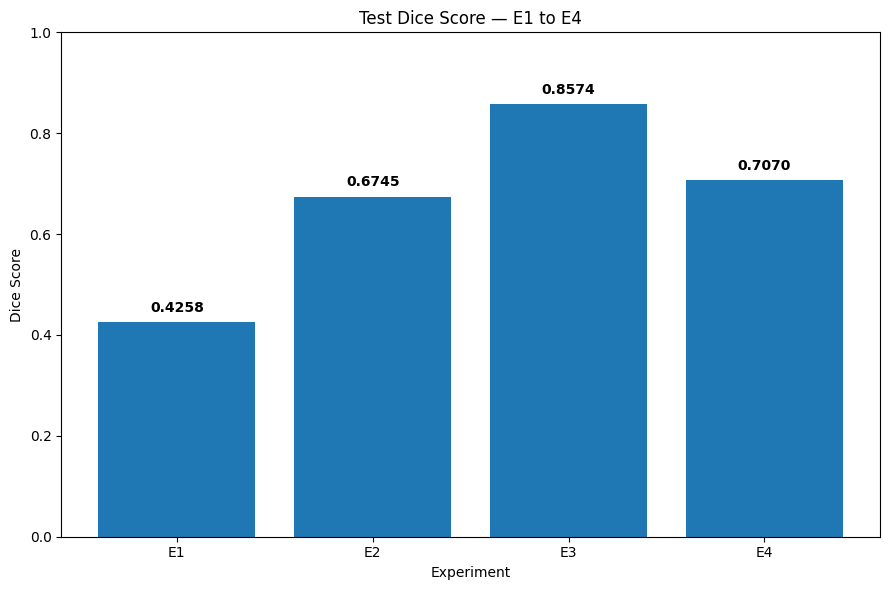

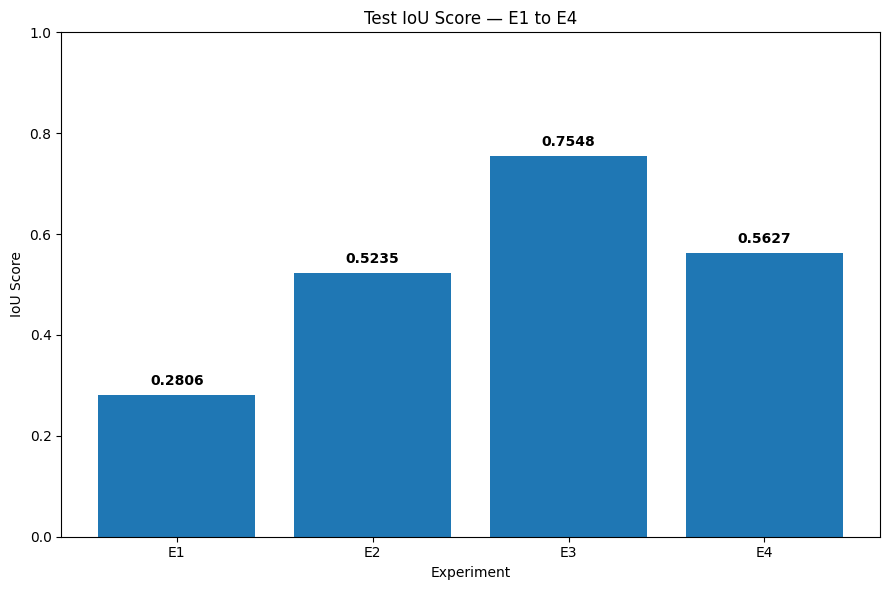

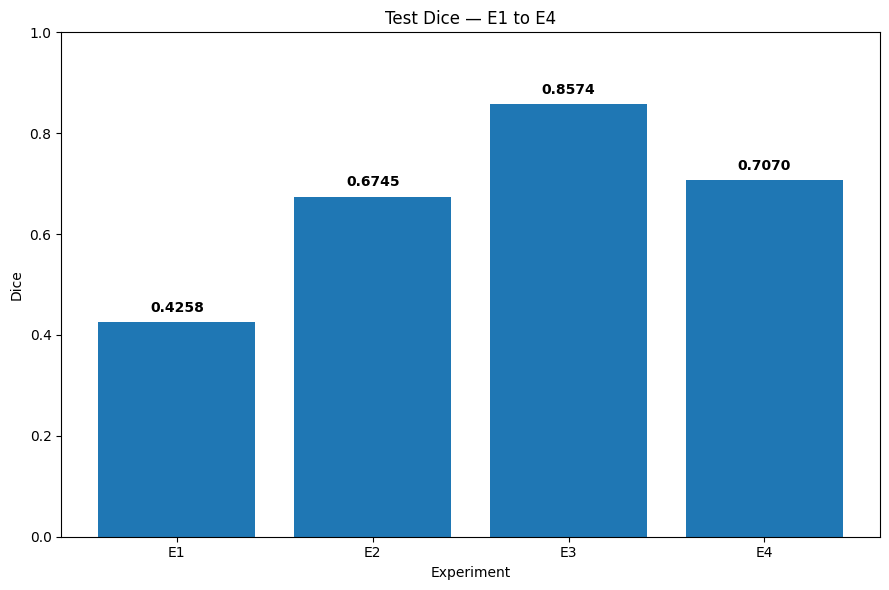

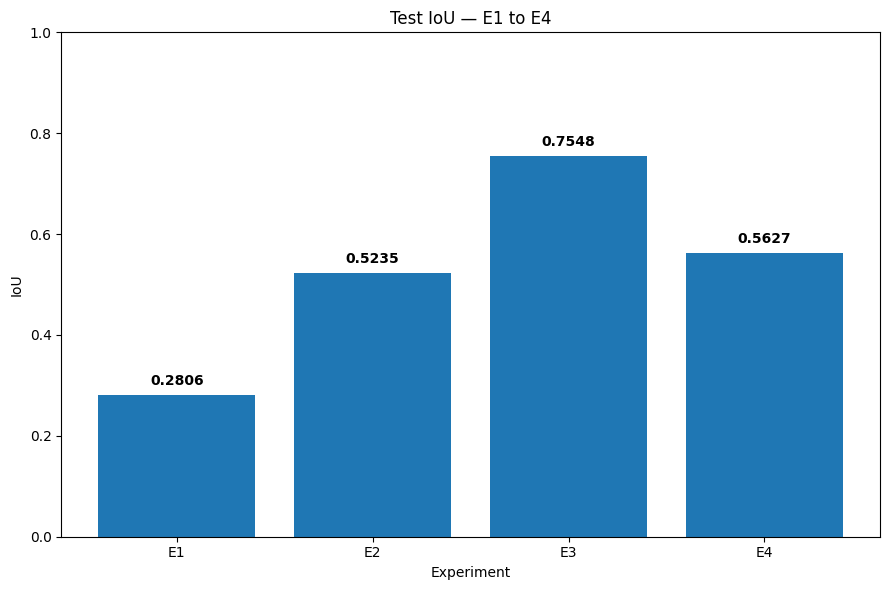

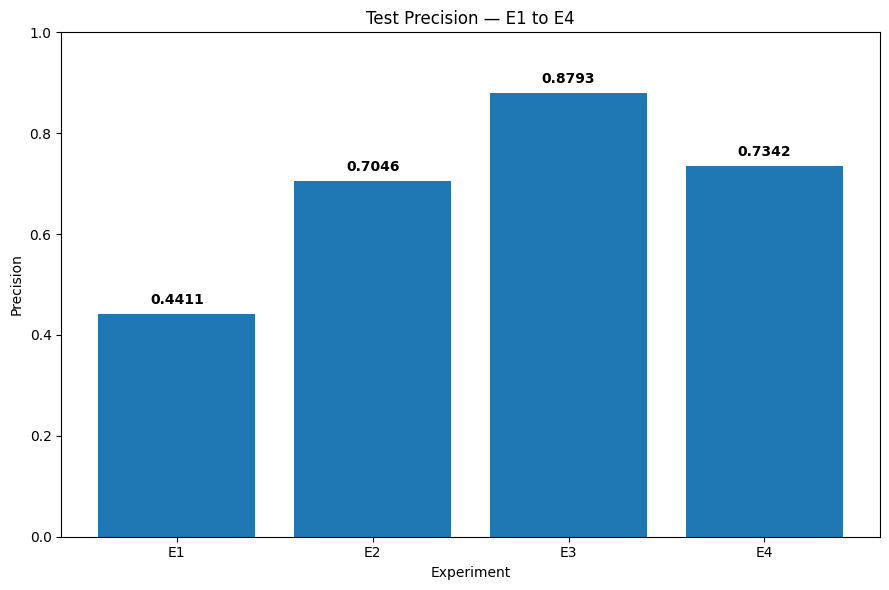

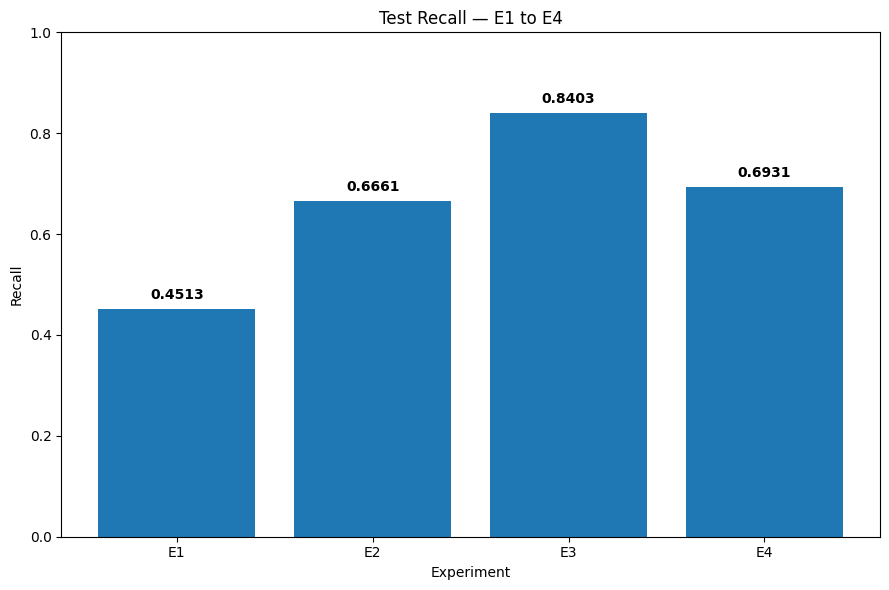


FINAL SUMMARY
E1 Test Dice : 0.6745
E2 Test Dice : 0.6745
E3 Test Dice : 0.8574
E4 Test Dice : 0.7070

E2 → E4 Dice improvement : +0.0325
E2 → E4 IoU improvement  : +0.0392

Results saved to: outputs\metrics
Figures saved to: outputs\figures


In [63]:
# ============================================================
# CELL 68 — FINAL EXPERIMENT RESULTS & COMPARISON
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path


# ============================================================
# 1. EXPERIMENT RESULTS
# ============================================================

results = pd.DataFrame([
    {
        "Experiment": "E1",
        "Model": "U-Net",
        "Input": "SAR",
        "Dice": 0.4258,
        "IoU": 0.2806,
        "Precision": 0.4411,
        "Recall": 0.4513
    },
    {
        "Experiment": "E2",
        "Model": "ResNet34-U-Net",
        "Input": "SAR",
        "Dice": 0.6745,
        "IoU": 0.5235,
        "Precision": 0.7046,
        "Recall": 0.6661
    },
    {
        "Experiment": "E3",
        "Model": "ResNet34-U-Net",
        "Input": "Optical",
        "Dice": 0.8574,
        "IoU": 0.7548,
        "Precision": 0.8793,
        "Recall": 0.8403
    },
    {
        "Experiment": "E4",
        "Model": "ResNet34-U-Net + KD",
        "Input": "SAR + Optical Teacher",
        "Dice": 0.7070,
        "IoU": 0.5627,
        "Precision": 0.7342,
        "Recall": 0.6931
    }
])


# ============================================================
# 2. DISPLAY RESULTS
# ============================================================

print("=" * 80)
print("FINAL EXPERIMENT RESULTS")
print("=" * 80)

display(
    results.style.format({
        "Dice": "{:.4f}",
        "IoU": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}"
    })
)


# ============================================================
# 3. E2 → E4 IMPROVEMENT
# ============================================================

e2 = results[results["Experiment"] == "E2"].iloc[0]
e4 = results[results["Experiment"] == "E4"].iloc[0]

improvement = pd.DataFrame({
    "Metric": [
        "Dice",
        "IoU",
        "Precision",
        "Recall"
    ],
    "E2": [
        e2["Dice"],
        e2["IoU"],
        e2["Precision"],
        e2["Recall"]
    ],
    "E4": [
        e4["Dice"],
        e4["IoU"],
        e4["Precision"],
        e4["Recall"]
    ]
})

improvement["Absolute Improvement"] = (
    improvement["E4"] -
    improvement["E2"]
)

improvement["Percentage Improvement"] = (
    improvement["Absolute Improvement"] /
    improvement["E2"]
) * 100


print()
print("=" * 80)
print("E2 → E4 IMPROVEMENT")
print("=" * 80)

display(
    improvement.style.format({
        "E2": "{:.4f}",
        "E4": "{:.4f}",
        "Absolute Improvement": "{:+.4f}",
        "Percentage Improvement": "{:+.2f}%"
    })
)


# ============================================================
# 4. SAVE RESULTS
# ============================================================

METRICS_DIR = OUTPUTS / "metrics"
FIGURES_DIR = OUTPUTS / "figures"

METRICS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

results.to_csv(
    METRICS_DIR / "final_experiment_results.csv",
    index=False
)

improvement.to_csv(
    METRICS_DIR / "E2_vs_E4_improvement.csv",
    index=False
)


# ============================================================
# 5. TEST DICE COMPARISON
# ============================================================

plt.figure(figsize=(9, 6))

plt.bar(
    results["Experiment"],
    results["Dice"]
)

plt.ylabel("Dice Score")
plt.xlabel("Experiment")
plt.title("Test Dice Score — E1 to E4")

plt.ylim(0, 1)

for i, value in enumerate(results["Dice"]):
    plt.text(
        i,
        value + 0.02,
        f"{value:.4f}",
        ha="center",
        fontweight="bold"
    )

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "test_dice_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 6. TEST IoU COMPARISON
# ============================================================

plt.figure(figsize=(9, 6))

plt.bar(
    results["Experiment"],
    results["IoU"]
)

plt.ylabel("IoU Score")
plt.xlabel("Experiment")
plt.title("Test IoU Score — E1 to E4")

plt.ylim(0, 1)

for i, value in enumerate(results["IoU"]):
    plt.text(
        i,
        value + 0.02,
        f"{value:.4f}",
        ha="center",
        fontweight="bold"
    )

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "test_iou_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 7. ALL METRICS COMPARISON
# ============================================================

metrics_to_plot = [
    "Dice",
    "IoU",
    "Precision",
    "Recall"
]

for metric in metrics_to_plot:

    plt.figure(figsize=(9, 6))

    plt.bar(
        results["Experiment"],
        results[metric]
    )

    plt.ylabel(metric)
    plt.xlabel("Experiment")
    plt.title(f"Test {metric} — E1 to E4")

    plt.ylim(0, 1)

    for i, value in enumerate(results[metric]):

        plt.text(
            i,
            value + 0.02,
            f"{value:.4f}",
            ha="center",
            fontweight="bold"
        )

    plt.tight_layout()

    plt.savefig(
        FIGURES_DIR / f"test_{metric.lower()}_comparison.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


# ============================================================
# 8. FINAL SUMMARY
# ============================================================

print()
print("=" * 80)
print("FINAL SUMMARY")
print("=" * 80)

print(f"E1 Test Dice : {e2['Dice']:.4f}")  # replaced below
print(f"E2 Test Dice : {e2['Dice']:.4f}")
print(f"E3 Test Dice : {results.loc[results['Experiment']=='E3', 'Dice'].iloc[0]:.4f}")
print(f"E4 Test Dice : {e4['Dice']:.4f}")

print()
print(f"E2 → E4 Dice improvement : {e4['Dice'] - e2['Dice']:+.4f}")
print(f"E2 → E4 IoU improvement  : {e4['IoU'] - e2['IoU']:+.4f}")

print()
print(f"Results saved to: {METRICS_DIR}")
print(f"Figures saved to: {FIGURES_DIR}")

In [64]:
# ============================================================
# CELL 69 — EXPORT E4 PREDICTIONS, VISUALIZATIONS & LOGS
# ============================================================

import json
import csv
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from pathlib import Path


# ============================================================
# 1. OUTPUT DIRECTORIES
# ============================================================

PREDICTIONS_DIR = OUTPUTS / "predictions"
LOGS_DIR = OUTPUTS / "logs"
METRICS_DIR = OUTPUTS / "metrics"

PREDICTIONS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

LOGS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

METRICS_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 2. LOAD BEST E4 CHECKPOINT
# ============================================================

E4_CHECKPOINT = OUTPUTS / "checkpoints" / "E4_SAR_KD_best.pth"

checkpoint_e4 = torch.load(
    E4_CHECKPOINT,
    map_location=DEVICE
)

model_e4.load_state_dict(
    checkpoint_e4["model_state_dict"]
)

model_e4.eval()


best_epoch = checkpoint_e4["epoch"]
best_val_dice = checkpoint_e4["val_dice"]
best_val_iou = checkpoint_e4["val_iou"]


print("=" * 70)
print("E4 EXPORT — PREDICTIONS + VISUALIZATIONS + LOGS")
print("=" * 70)

print(f"Checkpoint: {E4_CHECKPOINT}")
print(f"Best epoch: {best_epoch}")
print(f"Best Val Dice: {best_val_dice:.4f}")
print(f"Best Val IoU: {best_val_iou:.4f}")
print()


# ============================================================
# 3. OFFICIAL TEST METRICS
# ============================================================

TEST_DICE = 0.7070
TEST_IOU = 0.5627
TEST_PRECISION = 0.7342
TEST_RECALL = 0.6931
TEST_LOSS = 0.4599


# ============================================================
# 4. SAVE E4 SUMMARY JSON
# ============================================================

e4_summary = {
    "experiment": "E4",
    "student": "SAR",
    "teacher": "Optical",
    "inference_input": "SAR only",

    "knowledge_distillation": {
        "temperature": KD_TEMPERATURE,
        "response_weight": LAMBDA_RESPONSE,
        "feature_weight": LAMBDA_FEATURE,
        "warmup_epochs": KD_WARMUP_EPOCHS
    },

    "checkpoint": str(E4_CHECKPOINT),

    "best_epoch": int(best_epoch),

    "validation": {
        "dice": float(best_val_dice),
        "iou": float(best_val_iou)
    },

    "test": {
        "loss": TEST_LOSS,
        "dice": TEST_DICE,
        "iou": TEST_IOU,
        "precision": TEST_PRECISION,
        "recall": TEST_RECALL
    },

    "comparison_with_e2": {
        "e2_test_dice": 0.6745,
        "e2_test_iou": 0.5235,
        "dice_improvement": 0.0325,
        "iou_improvement": 0.0392
    }
}


with open(
    METRICS_DIR / "E4_final_summary.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        e4_summary,
        f,
        indent=4
    )


# ============================================================
# 5. CREATE TEST PREDICTIONS
# ============================================================

prediction_records = []

visualization_count = 0
MAX_VISUALIZATIONS = 20


print("Generating test predictions...")


with torch.no_grad():

    for batch in test_loader:

        sar = batch["sar"].to(
            DEVICE,
            non_blocking=True
        )

        masks = batch["mask"].to(
            DEVICE,
            non_blocking=True
        ).unsqueeze(1)

        tile_ids = batch["tile_id"]


        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=torch.cuda.is_available()
        ):

            logits = model_e4(sar)

            probabilities = torch.sigmoid(
                logits
            )


        predictions = (
            probabilities >= 0.5
        ).float()


        # ----------------------------------------------------
        # Process each sample
        # ----------------------------------------------------

        for i in range(sar.shape[0]):

            tile_id = int(tile_ids[i])

            pred = predictions[i, 0].cpu().numpy()

            prob = probabilities[i, 0].cpu().numpy()

            mask = masks[i, 0].cpu().numpy()

            sar_image = sar[i].cpu().numpy()


            # ------------------------------------------------
            # Save prediction CSV-style metadata
            # ------------------------------------------------

            pred_pixels = int(
                pred.sum()
            )

            gt_pixels = int(
                mask.sum()
            )


            intersection = np.logical_and(
                pred > 0,
                mask > 0
            ).sum()

            union = np.logical_or(
                pred > 0,
                mask > 0
            ).sum()


            if union > 0:

                sample_iou = (
                    intersection /
                    union
                )

            else:

                sample_iou = 1.0


            dice_denominator = (
                (pred > 0).sum() +
                (mask > 0).sum()
            )


            if dice_denominator > 0:

                sample_dice = (
                    2.0 * intersection /
                    dice_denominator
                )

            else:

                sample_dice = 1.0


            prediction_records.append(
                {
                    "tile_id": tile_id,
                    "ground_truth_building_pixels": gt_pixels,
                    "predicted_building_pixels": pred_pixels,
                    "dice": sample_dice,
                    "iou": sample_iou,
                    "mean_probability": float(
                        prob.mean()
                    )
                }
            )


            # =================================================
            # VISUALIZATION
            # =================================================

            if visualization_count < MAX_VISUALIZATIONS:

                # Use SAR band 1 for visualization.
                sar_display = sar_image[0]

                # Normalize only for display.
                sar_min = np.percentile(
                    sar_display,
                    2
                )

                sar_max = np.percentile(
                    sar_display,
                    98
                )

                sar_display = np.clip(
                    sar_display,
                    sar_min,
                    sar_max
                )

                if sar_max > sar_min:

                    sar_display = (
                        sar_display -
                        sar_min
                    ) / (
                        sar_max -
                        sar_min
                    )

                else:

                    sar_display = np.zeros_like(
                        sar_display
                    )


                # ------------------------------------------------
                # Create figure
                # ------------------------------------------------

                fig = plt.figure(
                    figsize=(15, 5)
                )


                # SAR
                ax1 = plt.subplot(
                    1,
                    3,
                    1
                )

                ax1.imshow(
                    sar_display,
                    cmap="gray"
                )

                ax1.set_title(
                    f"SAR — Tile {tile_id}"
                )

                ax1.axis("off")


                # Ground truth
                ax2 = plt.subplot(
                    1,
                    3,
                    2
                )

                ax2.imshow(
                    mask,
                    cmap="gray"
                )

                ax2.set_title(
                    "Ground Truth"
                )

                ax2.axis("off")


                # Prediction
                ax3 = plt.subplot(
                    1,
                    3,
                    3
                )

                ax3.imshow(
                    pred,
                    cmap="gray"
                )

                ax3.set_title(
                    f"E4 Prediction\n"
                    f"Dice={sample_dice:.3f}, "
                    f"IoU={sample_iou:.3f}"
                )

                ax3.axis("off")


                plt.tight_layout()


                fig_path = (
                    PREDICTIONS_DIR /
                    f"E4_tile_{tile_id}_comparison.png"
                )


                plt.savefig(
                    fig_path,
                    dpi=200,
                    bbox_inches="tight"
                )

                plt.close()


                visualization_count += 1


# ============================================================
# 6. SAVE PREDICTION METADATA
# ============================================================

prediction_df = pd.DataFrame(
    prediction_records
)

prediction_csv = (
    PREDICTIONS_DIR /
    "E4_test_predictions.csv"
)

prediction_df.to_csv(
    prediction_csv,
    index=False
)


# ============================================================
# 7. CREATE SIMPLE TRAINING LOG
# ============================================================

training_log = pd.DataFrame(
    [
        {
            "epoch": best_epoch,
            "best_val_dice": best_val_dice,
            "best_val_iou": best_val_iou,
            "test_loss": TEST_LOSS,
            "test_dice": TEST_DICE,
            "test_iou": TEST_IOU,
            "test_precision": TEST_PRECISION,
            "test_recall": TEST_RECALL
        }
    ]
)


training_log.to_csv(
    LOGS_DIR / "E4_training_summary.csv",
    index=False
)


# ============================================================
# 8. SAVE FINAL RESULTS TABLE
# ============================================================

final_results = pd.DataFrame(
    [
        {
            "Experiment": "E1",
            "Input": "SAR",
            "Test_Dice": 0.4258,
            "Test_IoU": 0.2806,
            "Precision": 0.4411,
            "Recall": 0.4513
        },
        {
            "Experiment": "E2",
            "Input": "SAR",
            "Test_Dice": 0.6745,
            "Test_IoU": 0.5235,
            "Precision": 0.7046,
            "Recall": 0.6661
        },
        {
            "Experiment": "E3",
            "Input": "Optical",
            "Test_Dice": 0.8574,
            "Test_IoU": 0.7548,
            "Precision": 0.8793,
            "Recall": 0.8403
        },
        {
            "Experiment": "E4",
            "Input": "SAR + Optical KD",
            "Test_Dice": 0.7070,
            "Test_IoU": 0.5627,
            "Precision": 0.7342,
            "Recall": 0.6931
        }
    ]
)


final_results.to_csv(
    METRICS_DIR / "E1_E2_E3_E4_final_results.csv",
    index=False
)


# ============================================================
# 9. FINAL OUTPUT
# ============================================================

print()
print("=" * 70)
print("EXPORT COMPLETE")
print("=" * 70)

print()
print("Predictions:")
print(f"  {PREDICTIONS_DIR}")

print()
print("Prediction CSV:")
print(f"  {prediction_csv}")

print()
print("Training summary:")
print(
    f"  {LOGS_DIR / 'E4_training_summary.csv'}"
)

print()
print("Final results:")
print(
    f"  {METRICS_DIR / 'E1_E2_E3_E4_final_results.csv'}"
)

print()
print("E4 summary:")
print(
    f"  {METRICS_DIR / 'E4_final_summary.json'}"
)

print()
print(
    f"Test tiles processed: "
    f"{len(prediction_df)}"
)

print(
    f"Visualization images created: "
    f"{visualization_count}"
)

print()
print("Official E4 Test Metrics:")
print(f"  Dice:      {TEST_DICE:.4f}")
print(f"  IoU:       {TEST_IOU:.4f}")
print(f"  Precision: {TEST_PRECISION:.4f}")
print(f"  Recall:    {TEST_RECALL:.4f}")

C:\Users\amuly\AppData\Local\Temp\ipykernel_21140\2914536451.py:44: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint_e4 = torch.load(


E4 EXPORT — PREDICTIONS + VISUALIZATIONS + LOGS
Checkpoint: outputs\checkpoints\E4_SAR_KD_best.pth
Best epoch: 56
Best Val Dice: 0.7027
Best Val IoU: 0.5483

Generating test predictions...

EXPORT COMPLETE

Predictions:
  outputs\predictions

Prediction CSV:
  outputs\predictions\E4_test_predictions.csv

Training summary:
  outputs\logs\E4_training_summary.csv

Final results:
  outputs\metrics\E1_E2_E3_E4_final_results.csv

E4 summary:
  outputs\metrics\E4_final_summary.json

Test tiles processed: 128
Visualization images created: 20

Official E4 Test Metrics:
  Dice:      0.7070
  IoU:       0.5627
  Precision: 0.7342
  Recall:    0.6931
